**Projet no. 2:** Implanter la méthode du gradient et du gradient stochastique pour le LASSO en s'appuyant sur le blog ici. Etudier numérique l'effet de la longeur du pas sur la convergence. Etudier l'effet du choix de la taille du mini-batch. Reproduire avec votre algorithme les expériences présentées dans la page du blog précédent.

 **source du cours que j'utilise :**
 - notes EE227C (chap. 2 « Gradient method », chap. 3 « Strong convexity », chap. 8 « Nesterov », chap. 10 « Stochastic optimization », 11.5 « Implicit regularization ») ;
 - notre cours (LASSO pdf p. 37 et 120, méthode proximale pdf p. 120-123, seuillage doux pdf p. 132, sous-gradient pdf p. 147, gradient stochastique pdf p. 118) ;
 - slides d'optimisation (LASSO p. 19-20, mini-batch p. 24-26).


In [118]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt


In [119]:

np.random.seed(1337)

kwargs = {'linewidth': 3.5}
font = {'weight': 'normal', 'size': 24}
matplotlib.rc('font', **font)

def error_plot(ys, yscale='log'):
    plt.figure(figsize=(8, 8))
    plt.xlabel('Step')
    plt.ylabel('Error')
    plt.yscale(yscale)
    plt.plot(range(len(ys)), ys, **kwargs)
    plt.show()


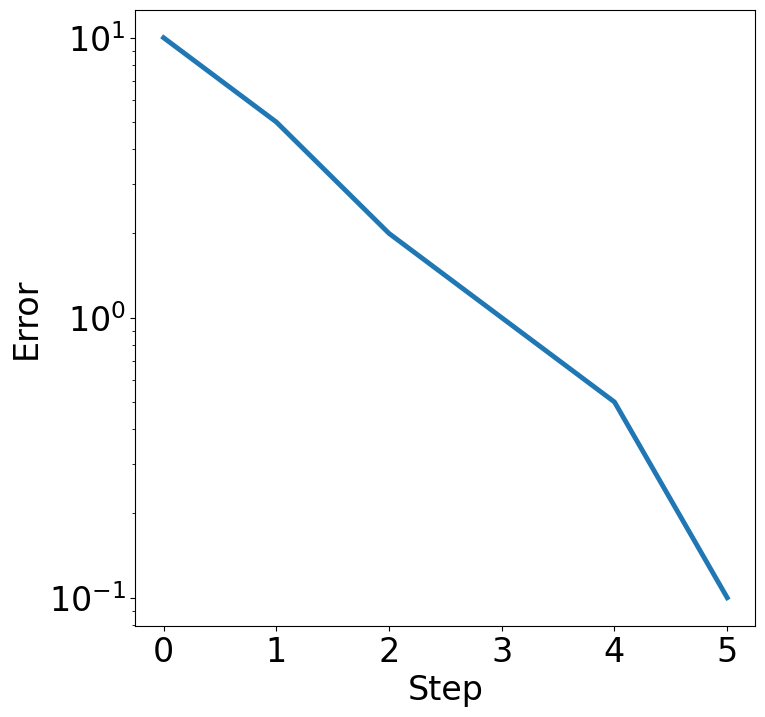

In [120]:
#exemple d'appel

ys = [10, 5, 2, 1, 0.5, 0.1]
error_plot(ys)


## Projected gradient descent

We start with a basic implementation of projected gradient descent.

In [121]:
#Descente de gradient projetée: x_{k+1} = Proj( x_k - s_k * grad f(x_k) ).
#params:
# `steps` est la liste des pas : le nombre d'itérations vaut len(steps). Le budget est donc fixé à l'avance, il n'y a pas de critère d'arrêt.
# `proj` est l'identité par défaut. Plus loin, je passe un sous-gradient à la place du gradient-> on obtient la méthode du sous-gradient.
def gradient_descent(init, steps, grad, proj=lambda x: x):
    """Projected gradient descent.

    Inputs:
        initial: starting point
        steps: list of scalar step sizes
        grad: function mapping points to gradients
        proj (optional): function mapping points to points

    Returns:
        List of all points computed by projected gradient descent.
    """
    xs = [init]
    for step in steps:
        xs.append(proj(xs[-1] - step * grad(xs[-1])))
    return xs

> **Ce que j'ai compris:** C'est l'algorithme de base de tout le notebook: on avance dans la direction opposée au gradient, puis on projette pour rester dans l'ensemble admissible. Cette forme me servira pour la méthode proximale, le gradient proximal s'écrit exactement comme le gradient projeté, avec l'opérateur proximal à la place de la projection.

> **Critique:** Il n'y a aucun critère d'arrêt : on fixe le nombre d'itérations à l'avance sans savoir si on est près de la solution. Ce sera un vrai problème pour le LASSO. De plus, tous les itérés sont stockés, ce qui est correct ici mais pas pour un gros problème.

> Si on remplace le gradient par un *sous-gradient* (fonction non dérivable), les garanties de descente vues en cours ne s'appliquent plus telles quelles : c'est le point central de ce projet.

<a id="warmup"></a>
## Warm-up: Optimizing a quadratic

As a toy example, let's optimize $$f(x)=\frac12\|x\|^2,$$ which has the gradient map $\nabla f(x)=x.$

In [122]:
def quadratic(x):
    return 0.5*x.dot(x)

def quadratic_gradient(x):
    return x

Note the function is $1$-smooth and $1$-strongly convex. Our theorems would then suggest that we use a constant step size of $1.$ If you think about it, for this step size the algorithm will actually find the optimal solution in just one step.

In [123]:
x0 = np.random.normal(0, 1, (1000))
_, x1 = gradient_descent(x0, [1.0], quadratic_gradient)

Indeed, it does.

In [124]:
x1.all() == 0

np.True_

Let's say we don't have the right learning rate.

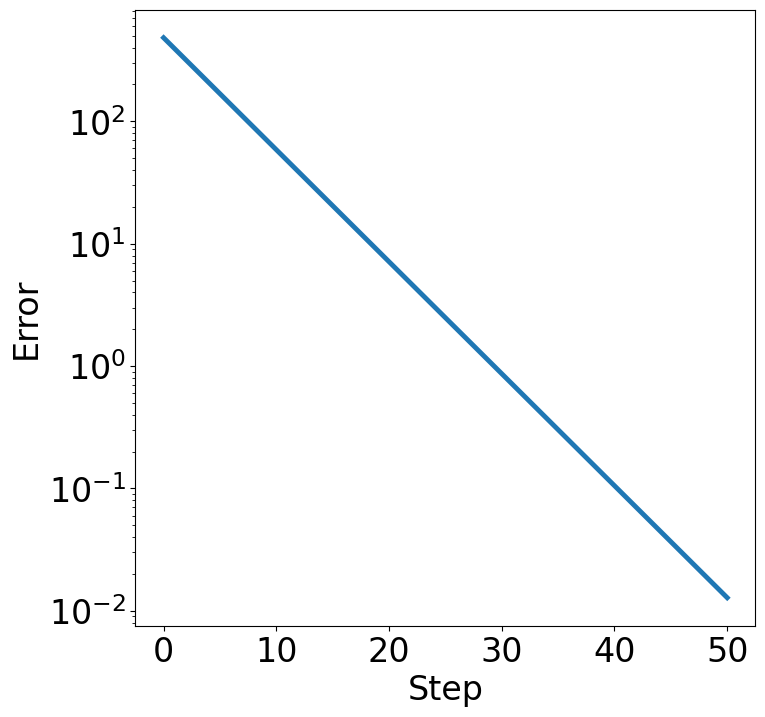

In [125]:
# Pas 0.1 < 2/L : convergence linéaire, f(x_k) = 0.81^k f(x_0), c'est-à-dire une droite en échelle logarithmique.
xs = gradient_descent(x0, [0.1]*50, quadratic_gradient)
error_plot([quadratic(x) for x in xs])

> **Ce que j'ai compris:** Ici x_{k+1} = (1 − s) x_k, donc f(x_k) = (1 − s)^{2k} f(x_0). Avec s = 1 on arrive en 0 en un pas ; avec s = 0,1, f est multipliée par 0,81 à chaque itération (0,81^50 ≈ 2,7·10⁻⁵ après 50 itérations). C'est le résultat du cours « fonction lisse et fortement convexe ⇒ convergence linéaire »

> **Interprétation.** La droite en échelle logarithmique est la signature d'une convergence linéaire. Le pas 1/L n'est « magique » ici que parce que L = μ = 1 : sur un vrai problème, un même pas ne convient pas à toutes les directions.

> **Critique.** Le test `x1.all() == 0` passe pour une mauvaise raison (voir le commentaire dans le code).
> les notes d'EE227C appellent β la constante de lissité et α la forte convexité. Je note plutôt L et μ, parce que α est déjà le paramètre de régularisation du LASSO.

### Constrained optimization

Let's say we want to optimize the function inside some affine subspace. Recall that affine subspaces are convex sets. Below we pick a random low dimensional affine subspace $b+U$ and define the corresponding linear projection operator.

In [126]:
# U : base orthonormale d'un sous-espace aléatoire de dimension 100 de R^1000 ; b : décalage.
# Projection orthogonale sur le sous-espace affine b + U : proj(x) = b + U U^T (x - b).
# U is an orthonormal basis of a random 100-dimensional subspace.
U = np.linalg.qr(np.random.normal(0, 1, (1000, 100)))[0]
b = np.random.normal(0, 1, 1000)

def proj(x):
    """Projection of x onto an affine subspace"""
    return b + U.dot(U.T).dot(x-b)

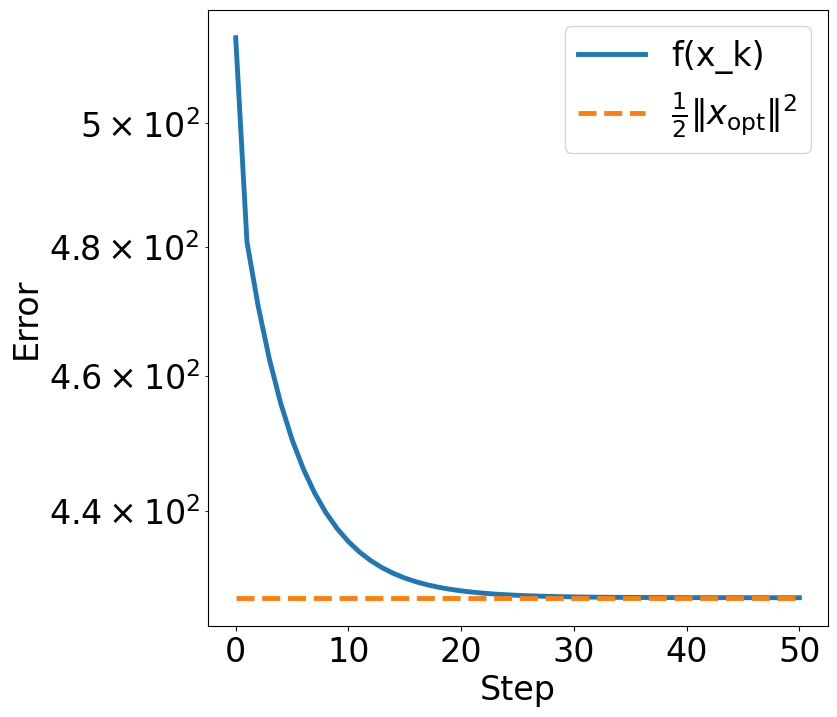

In [127]:
# Même fonction quadratique, mais on reste dans le sous-espace affine b + U :
# l'optimum est le point de b + U le plus proche de l'origine, soit proj(0).
x0 = np.random.normal(0, 1, (1000))
xs = gradient_descent(x0, [0.1]*50, quadratic_gradient, proj)

# the optimal solution is the projection of the origin
x_opt = proj(0)

# Une seule figure : courbe de l'objectif + valeur optimale
plt.figure(figsize=(8, 8))
plt.yscale('log')
plt.plot([quadratic(x) for x in xs], linewidth=3.5, label='f(x_k)')
plt.plot([quadratic(x_opt)] * len(xs), '--', linewidth=3.5,
         label=r'$\frac{1}{2}\|x_{\mathrm{opt}}\|^2$')
plt.xlabel('Step')
plt.ylabel('Error')
plt.legend()

The orangle line shows the optimal error, which the algorithm reaches quickly. The iterates also converge to the optimal solution in domain as the following plot shows.

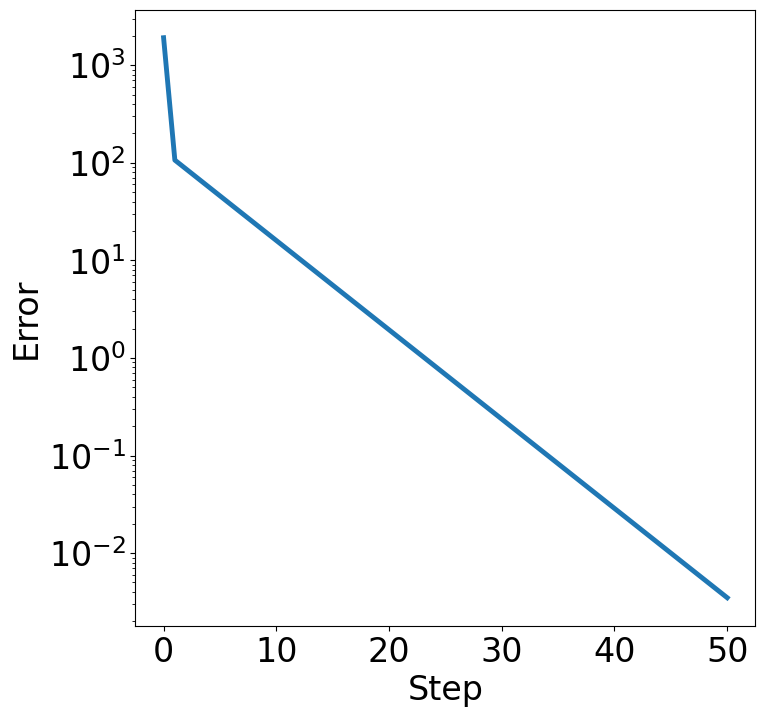

In [128]:
error_plot([np.linalg.norm(x_opt-x)**2 for x in xs])

> **Ce que j'ai compris:** Pour un ensemble convexe, projeter après chaque pas conserve la convergence. Ici la projection est une simple formule matricielle, donc peu coûteuse.

> Il y a deux notions de convergence : *en objectif* (f(x_k) → f*) et *en domaine* (x_k → x*). La seconde est plus exigeante. Le notebook montre les deux, et elles se séparent dans le cas sous-déterminé puis pour le LASSO.

<a id="least-squares"></a>
## Least Squares

One of the most fundamental data analysis tools is *linear least squares*. Given an $m\times n$ matrix $A$ and a vector $b$ our goal is to find a vector $x\in\mathbb{R}^n$ that minimizes the following objective:

<p>
$$f(x) = \frac 1{2m}\sum_{i=1}^m (a_i^\top x - b_j)^2
=\frac1{2m}\|Ax-b\|^2$$
</p>

We can verify that $\nabla f(x) = A^\top(Ax-b)$ and
$\nabla^2 f(x) = A^\top A.$

Hence, the objective is $\beta$-smooth with
$\beta=\lambda_{\mathrm{max}}(A^\top A)$, and $\alpha$-strongly convex with $\alpha=\lambda_{\mathrm{min}}(A^\top A)$.

> **Ce que j'ai compris:** Le code utilise l'objectif divisé par m : f(x) = (1/2m)‖Ax − b‖². Le gradient est donc ∇f(x) = Aᵀ(Ax − b)/m et la hessienne AᵀA/m ; la constante de lissité est L = λ_max(AᵀA)/m et celle de forte convexité μ = λ_min(AᵀA)/m. Le texte oublie ce 1/m alors que le code le met. De plus, les lettres α et β du texte entrent en conflit avec le paramètre de régularisation α utilisé plus loin.

In [129]:
# Attention : ces deux fonctions utilisent la variable GLOBALE m (nombre de lignes), définie dans la cellule suivante.
# C'est une dépendance cachée : si m change entre deux cellules, les résultats changent sans qu'on le voie.

def least_squares(A, b, x):
    """Least squares objective."""
    return (0.5/m) * np.linalg.norm(A.dot(x)-b)**2

def least_squares_gradient(A, b, x):
    """Gradient of least squares objective at x."""
    return A.T.dot(A.dot(x)-b)/m

### Overdetermined case $m\ge n$

In [130]:
# Cas surdéterminé (m >= n) : AᵀA/m est définie positive, donc f est fortement convexe.
# b = A x_opt + bruit gaussien (écart-type 0.1). x_opt est le VRAI paramètre, pas le minimiseur des moindres carrés (à cause du bruit).
m, n = 1000, 100
A = np.random.normal(0, 1, (m, n))
x_opt = np.random.normal(0, 1, n)
noise = np.random.normal(0, 0.1, m)
b = A.dot(x_opt) + noise
objective = lambda x: least_squares(A, b, x)
gradient = lambda x: least_squares_gradient(A, b, x)

#### Convergence in objective

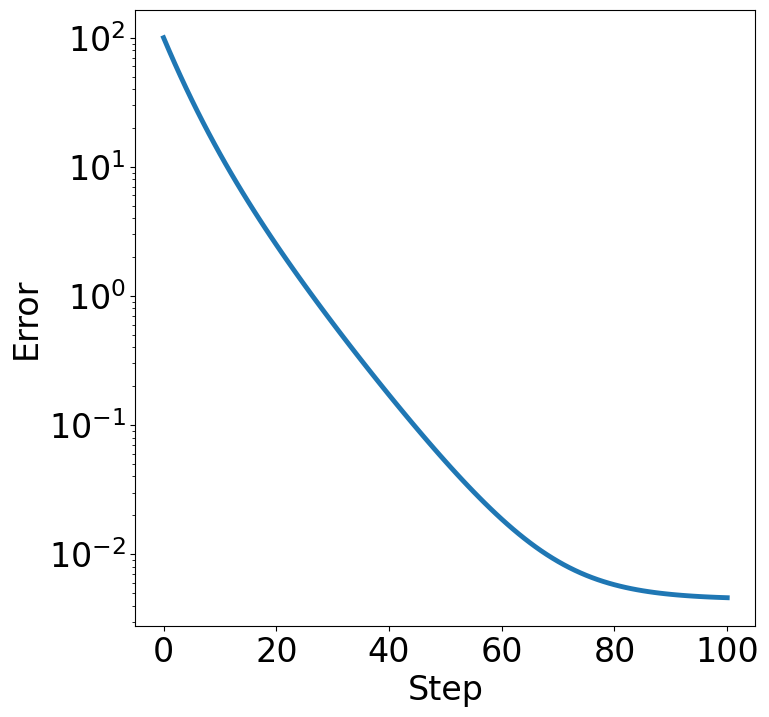

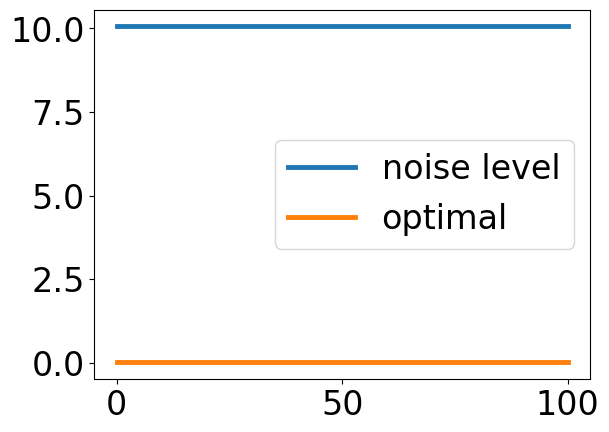

In [131]:
# la ligne 'noise level' trace ||noise||^2 SANS division par 2m, alors que l'objectif est divisé par 2m.
# Elle n'est donc pas à la même échelle que la courbe
x0 = np.random.normal(0, 1, n)
xs = gradient_descent(x0, [0.1]*100, gradient)
error_plot([objective(x) for x in xs])
plt.plot(range(len(xs)), [np.linalg.norm(noise)**2]*len(xs),
        label='noise level', **kwargs)
plt.plot(range(len(xs)), [least_squares(A,b,x_opt)]*len(xs),
        label='optimal', **kwargs)
_ = plt.legend()

#### Convergence in domain

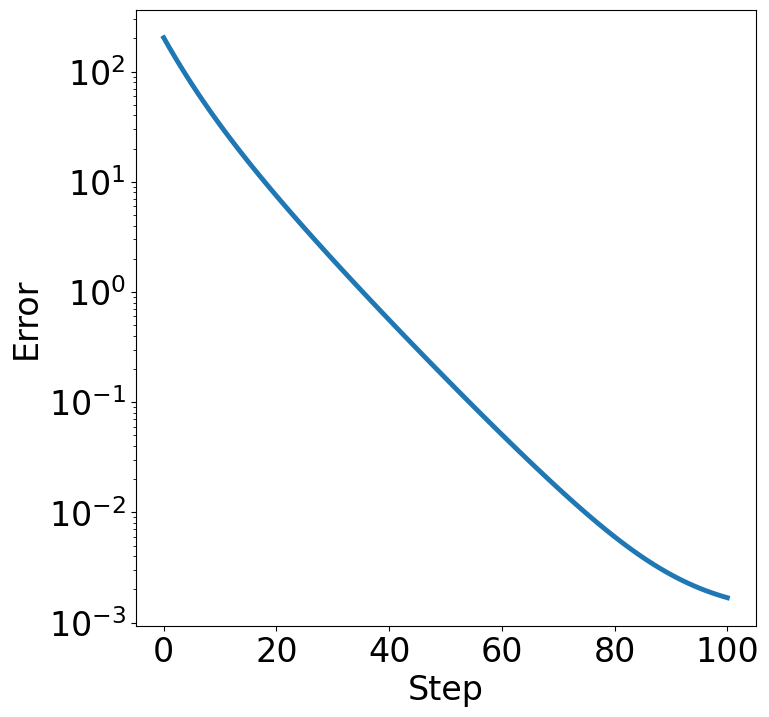

In [132]:
# Convergence en domaine vers x_opt (le vrai paramètre) : on ne peut pas descendre sous ||x_moindres_carrés - x_vrai||^2, à cause du bruit.

error_plot([np.linalg.norm(x-x_opt)**2 for x in xs])

In [133]:
# j'ai rajouté cette cellule pour vérifier : constantes L et mu, contraction du pas, « plancher de bruit » (cas surdéterminé, m = 1000, n = 100)
H = A.T.dot(A) / m                                    # hessienne de f (avec le facteur 1/m)
ev = np.linalg.eigvalsh(H)
L_, mu_ = ev.max(), ev.min()
print("L = %.3f, mu = %.3f, conditionnement = %.2f" % (L_, mu_, L_ / mu_))
print("1/L = %.3f ; 2/L = %.3f ; pas utilise = 0.1 -> contraction par iteration max|1 - s*lambda| = %.3f" % (1 / L_, 2 / L_, np.max(np.abs(1 - 0.1 * ev))))
x_ls = np.linalg.lstsq(A, b, rcond=None)[0]           # vrai minimiseur des moindres carres
print("||noise||^2            = %.3f   <- ce que trace la ligne 'noise level' (sans 1/(2m))" % np.linalg.norm(noise) ** 2)
print("||noise||^2 / (2m)     = %.5f   <- meme echelle que l'objectif" % (np.linalg.norm(noise) ** 2 / (2 * m)))
print("f(x_vrai)              = %.5f" % least_squares(A, b, x_opt))
print("f(x_moindres_carres)   = %.5f  (minimum exact : <= f(x_vrai))" % least_squares(A, b, x_ls))
print("||x_MC - x_vrai||^2    = %.5f  <- plateau de la courbe 'convergence en domaine'" % np.linalg.norm(x_ls - x_opt) ** 2)

L = 1.717, mu = 0.481, conditionnement = 3.57
1/L = 0.583 ; 2/L = 1.165 ; pas utilise = 0.1 -> contraction par iteration max|1 - s*lambda| = 0.952
||noise||^2            = 10.056   <- ce que trace la ligne 'noise level' (sans 1/(2m))
||noise||^2 / (2m)     = 0.00503   <- meme echelle que l'objectif
f(x_vrai)              = 0.00503
f(x_moindres_carres)   = 0.00447  (minimum exact : <= f(x_vrai))
||x_MC - x_vrai||^2    = 0.00117  <- plateau de la courbe 'convergence en domaine'


> **Ce que j'ai compris:** Pour m ≥ n, la hessienne AᵀA/m est définie positive : f est μ-fortement convexe et L-lisse avec μ > 0. D'après le cours, la descente de gradient converge alors *linéairement* vers l'unique minimiseur. Le pas 0,1 est inférieur à 1/L, donc la contraction est garantie.

> **Interprétation.** La cellule de vérification affiche L, μ et le facteur de contraction par itération. L'objectif ne peut pas descendre sous le niveau du bruit : le minimum exact (moindres carrés) est un peu inférieur à f(x_vrai), car il ajuste aussi une partie du bruit.

> **Critique.** La ligne « noise level » du premier graphique n'est pas à la même échelle que l'objectif (‖noise‖² au lieu de ‖noise‖²/(2m)) : elle ne représente donc pas le bon plancher. De même, la convergence « en domaine » est mesurée vers le vrai paramètre et pas vers le minimiseur : le plateau observé n'est pas une erreur de l'algorithme, c'est l'effet du bruit.

### Underdetermined case $m < n$

In the underdetermined case, the least squares objective is inevitably not strongly convex, since $A^\top A$ is a rank deficient matrix and hence $\lambda_{\mathrm{min}}(A^\top A)=0.$

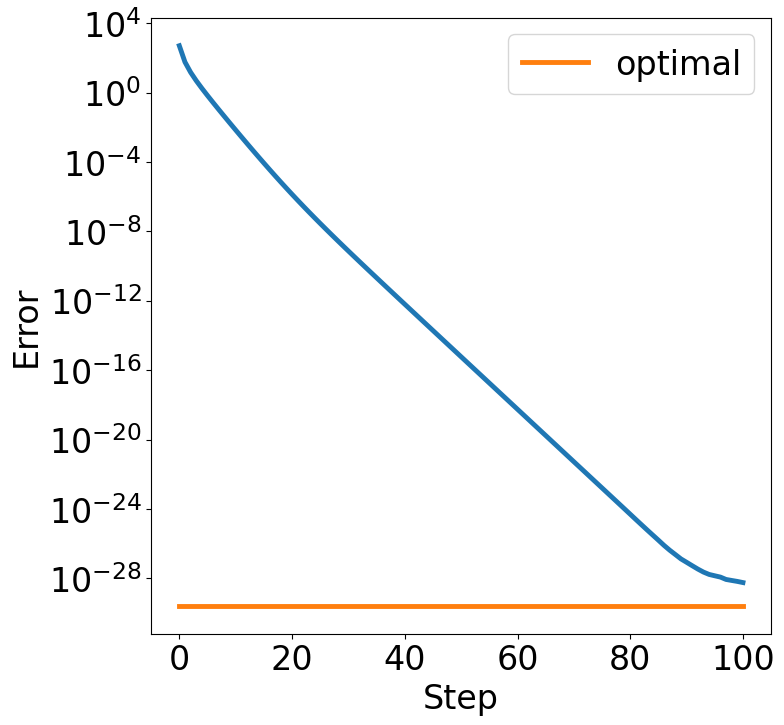

In [134]:
m, n = 100, 1000
A = np.random.normal(0, 1, (m, n))
b = np.random.normal(0, 1, m)
# The least norm solution is given by the pseudo-inverse
x_opt = np.linalg.pinv(A).dot(b)
objective = lambda x: least_squares(A, b, x)
gradient = lambda x: least_squares_gradient(A, b, x)
x0 = np.random.normal(0, 1, n)
xs = gradient_descent(x0, [0.1]*100, gradient)

# Tout est tracé dans UNE seule figure (au lieu de error_plot + plt.plot, qui s'affichent séparément chez vous)
f_opt = max(least_squares(A, b, x_opt), 1e-300)     # ~1e-30 : zéro à l'arrondi près (évite log(0))
plt.figure(figsize=(8, 8))
plt.yscale('log')
plt.xlabel('Step')
plt.ylabel('Error')
plt.plot(range(len(xs)), [objective(x) for x in xs], color='tab:blue', **kwargs)
plt.plot(range(len(xs)), [f_opt] * len(xs), color='tab:orange', label='optimal', **kwargs)
_ = plt.legend()

While we quickly reduce the error, we don't actually converge in domain to the least norm solution. This is just because the function is no longer strongly convex in the underdetermined case.

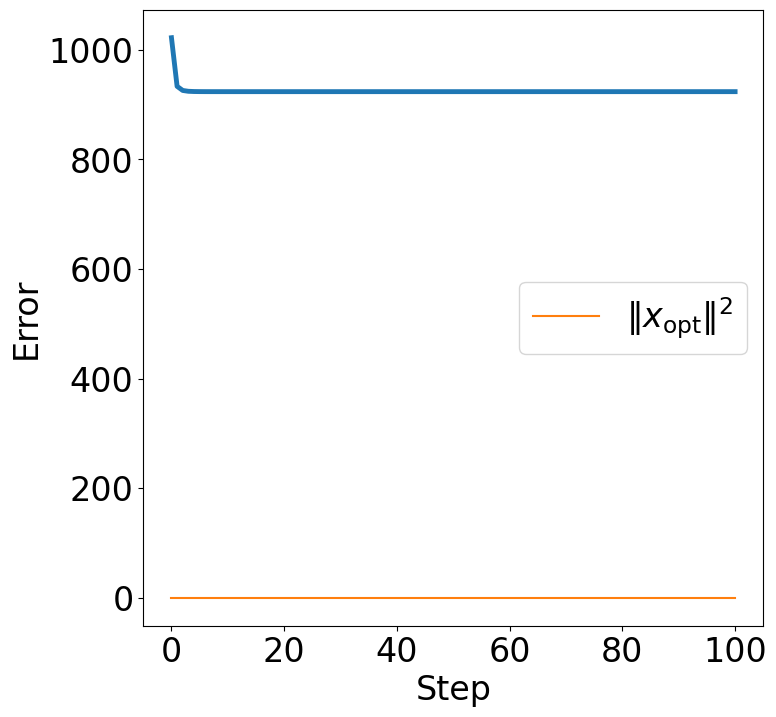

In [135]:
# Convergence en domaine : distance au minimiseur de norme minimale (échelle linéaire)
plt.figure(figsize=(8, 8))
plt.xlabel('Step')
plt.ylabel('Error')
plt.plot(range(len(xs)), [np.linalg.norm(x_opt - x)**2 for x in xs],
         color='tab:blue', **kwargs)
plt.plot(range(len(xs)), [np.linalg.norm(x_opt)**2] * len(xs),
         color='tab:orange', linewidth=1.5,
         label=r'$\|x_{\mathrm{opt}}\|^2$')
plt.legend()

In [136]:
# [Ajout] Vérification : ce qui reste exactement après convergence dans le cas sous-déterminé
P = np.eye(n) - np.linalg.pinv(A).dot(A)             # projecteur orthogonal sur le noyau de A
print("||P (x_k - x_0)||       = %.2e  -> les iteres ne bougent JAMAIS dans le noyau de A (le gradient est dans l'image de A^T)" % np.linalg.norm(P.dot(xs[-1] - xs[0])))
print("||x_final - x_opt||^2   = %.4f" % (np.linalg.norm(xs[-1] - x_opt) ** 2))
print("||P x_0||^2             = %.4f  -> l'erreur restante est exactement la composante de x_0 dans le noyau" % (np.linalg.norm(P.dot(xs[0])) ** 2))

||P (x_k - x_0)||       = 2.52e-14  -> les iteres ne bougent JAMAIS dans le noyau de A (le gradient est dans l'image de A^T)
||x_final - x_opt||^2   = 923.2907
||P x_0||^2             = 923.2907  -> l'erreur restante est exactement la composante de x_0 dans le noyau


> **Ce que j'ai compris** Le gradient Aᵀ(Ax − b)/m est toujours une combinaison des lignes de A. Les itérés x_k = x_0 + (combinaison des lignes de A) ne bougent donc jamais dans le noyau de A . La descente converge vers la solution exacte la plus proche de x_0, c'est-à-dire x_opt + P x_0 où P est la projection sur le noyau.

> **Interprétation.** C'est ce qui explique le plateau du graphique : l'erreur restante ‖x_final − x_opt‖² vaut exactement ‖P x_0‖², ce que la cellule de vérification confirme. Sans forte convexité, on converge en objectif mais pas vers un minimiseur précis.

>  Ce mécanisme est la clé pour comprendre le LASSO plus loin : dans le noyau de A, ni le terme de données ni son gradient n'agissent ; seule la pénalité ℓ1 peut faire bouger ces 900 coordonnées, et elle le fait lentement (de α·s par itération).

<a id="regularization"></a>

## $\ell_2$-regularized least squares

In the underdetermined case, it is often desirable to restore strong convexity of the objective function by adding an $\ell_2^2$-penality, also known as *Tikhonov regularization*, $\ell_2$-regularization, or *weight decay*.

<p>
$$\frac1{2m}\|Ax-b\|^2 + \frac{\alpha}2\|x\|^2$$
</p>

Note: With this modification the objective is $\alpha$-strongly convex again.


In [137]:
# Objectif ridge : f(x) = 1/(2m)||Ax-b||^2 + alpha/2 ||x||^2 ; gradient = A^T(Ax-b)/m + alpha*x.
# La pénalité ajoute alpha*I à la hessienne : f est alpha-fortement convexe (mu = alpha = 0.1), comme annoncé dans le texte.
def least_squares_l2(A, b, x, alpha=0.1):
    return least_squares(A, b, x) + (alpha/2) * x.dot(x)

def least_squares_l2_gradient(A, b, x, alpha=0.1):
    return least_squares_gradient(A, b, x) + alpha * x

Let's create a least squares instance.

In [138]:
# Instance sous-déterminée ; b est dans l'image de A (b = A x pour un certain x).

m, n = 100, 1000
A = np.random.normal(0, 1, (m, n))
b = A.dot(np.random.normal(0, 1, n))
objective = lambda x: least_squares_l2(A, b, x)
gradient = lambda x: least_squares_l2_gradient(A, b, x)

Note that we can find the optimal solution to the optimization problem in closed form without even running gradient descent by computing $x_{\mathrm{opt}}=(A^\top+\alpha I)^{-1}A^\top b.$ Please verify that this point is indeed optimal.

In [139]:
# cette forme fermée est incohérente avec l'objectif défini plus haut (cellule des fonctions ridge).
# L'optimum de f(x) = 1/(2m)||Ax-b||^2 + alpha/2||x||^2 est (A^T A + m*alpha*I)^{-1} A^T b ; le code calcule (A^T A + alpha*I)^{-1} A^T b : le facteur m est oublié.
x_opt = np.linalg.inv(A.T.dot(A) + 0.1*np.eye(1000)).dot(A.T).dot(b)

In [140]:
#Vérification demandée par le notebook (« Please verify that this point is indeed optimal ») : le gradient doit être nul à l'optimum
alpha_ = 0.1
grad_f = lambda x: least_squares_l2_gradient(A, b, x, alpha_)
x_ok = np.linalg.solve(A.T.dot(A) / m + alpha_ * np.eye(n), A.T.dot(b) / m)      # vrai minimiseur
print("||grad f(x_opt du notebook)|| = %.3e   <- devrait valoir ~0 si c'etait l'optimum" % np.linalg.norm(grad_f(x_opt)))
print("||grad f(x corrige)||         = %.3e" % np.linalg.norm(grad_f(x_ok)))
print("||x_opt notebook - x corrige||^2 = %.4f  -> plateau attendu sur la courbe 'convergence en domaine'" % (np.linalg.norm(x_opt - x_ok) ** 2))

||grad f(x_opt du notebook)|| = 1.026e+00   <- devrait valoir ~0 si c'etait l'optimum
||grad f(x corrige)||         = 5.781e-14
||x_opt notebook - x corrige||^2 = 0.0138  -> plateau attendu sur la courbe 'convergence en domaine'


Here's how gradient descent fares.

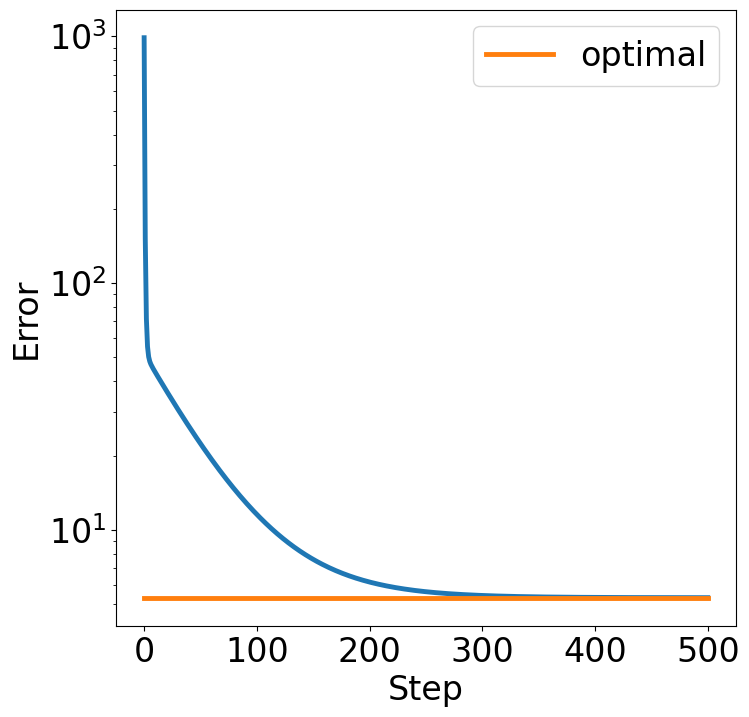

In [141]:
# Pas 0.1, 500 itérations. La ligne 'optimal' est le VRAI minimiseur de f(x) = 1/(2m)||Ax-b||^2 + alpha/2 ||x||^2,
# recalculé ici (le x_opt du notebook oublie le facteur m et dépend de l'ordre d'exécution des cellules).
alpha_ = 0.1
x_star = np.linalg.solve(A.T.dot(A) / m + alpha_ * np.eye(n), A.T.dot(b) / m)
f_star = least_squares_l2(A, b, x_star)

x0 = np.random.normal(0, 1, n)
xs = gradient_descent(x0, [0.1]*500, gradient)

plt.figure(figsize=(8, 8))
plt.yscale('log')
plt.xlabel('Step')
plt.ylabel('Error')
plt.plot(range(len(xs)), [objective(x) for x in xs], color='tab:blue', **kwargs)
plt.plot(range(len(xs)), [f_star] * len(xs), color='tab:orange', label='optimal', **kwargs)
_ = plt.legend()

You see that the error doesn't decrease below a certain level due to the regularization term. This is not a bad thing. In fact, the regularization term gives as *strong convexity* which leads to convergence in domain again:

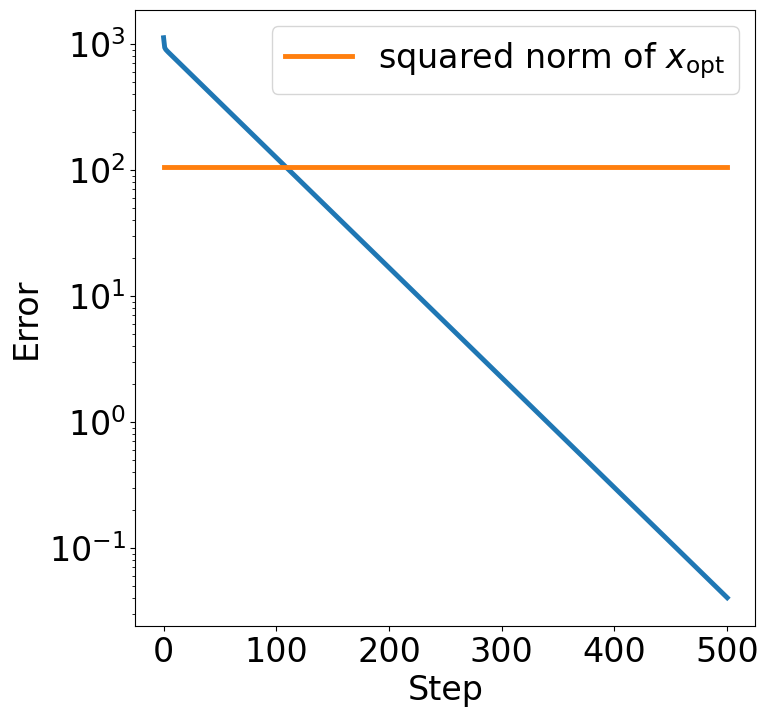

In [142]:
# Convergence en domaine vers le VRAI minimiseur du problème ridge (recalculé ici,
# pour ne pas dépendre du x_opt d'une autre cellule).
alpha_ = 0.1
x_star = np.linalg.solve(A.T.dot(A) / m + alpha_ * np.eye(n), A.T.dot(b) / m)

xs = gradient_descent(x0, [0.1]*500, gradient)

plt.figure(figsize=(8, 8))
plt.yscale('log')
plt.xlabel('Step')
plt.ylabel('Error')
plt.plot(range(len(xs)), [np.linalg.norm(x - x_star)**2 for x in xs], color='tab:blue', **kwargs)
plt.plot(range(len(xs)), [np.linalg.norm(x_star)**2] * len(xs), color='tab:orange',
         label=r'squared norm of $x_{\mathrm{opt}}$', **kwargs)
_ = plt.legend()

> **Ce que j'ai compris** La pénalité ℓ2 rend f fortement convexe (μ = α = 0,1), donc on retrouve la convergence linéaire *en domaine* vers l'unique minimiseur . La vitesse dépend de α·s : dans les directions du noyau de A, le facteur de contraction par itération est (1 − sα) = 0,99, donc il faut des centaines d'itérations (0,99^500 ≈ 7·10⁻³).

> **Critique:** La vérification montre que le x_opt du notebook n'est pas l'optimum de la fonction étudiée : le gradient en ce point n'est pas nul. L'erreur est petite en valeur relative, mais elle fait apparaître un plateau non nul sur la courbe « convergence en domaine ». Correction : (AᵀA + m·α·I)⁻¹Aᵀb, ou résoudre le système avec `np.linalg.solve`.
> Régulariser en ℓ2 revient à rendre le problème fortement convexe, donc à obtenir un minimiseur unique et une convergence linéaire. Le LASSO fait un autre choix : une pénalité ℓ1, non lisse, pour obtenir de la parcimonie.

<a id="implicit"></a>
## The magic of implicit regularization

Sometimes simply running gradient descent from a suitable initial point has a regularizing effect on its own **without introducing an explicit regularization term**.

We will see this below where we revisit the unregularized least squares objective, but initialize gradient descent from the origin rather than a random gaussian point.

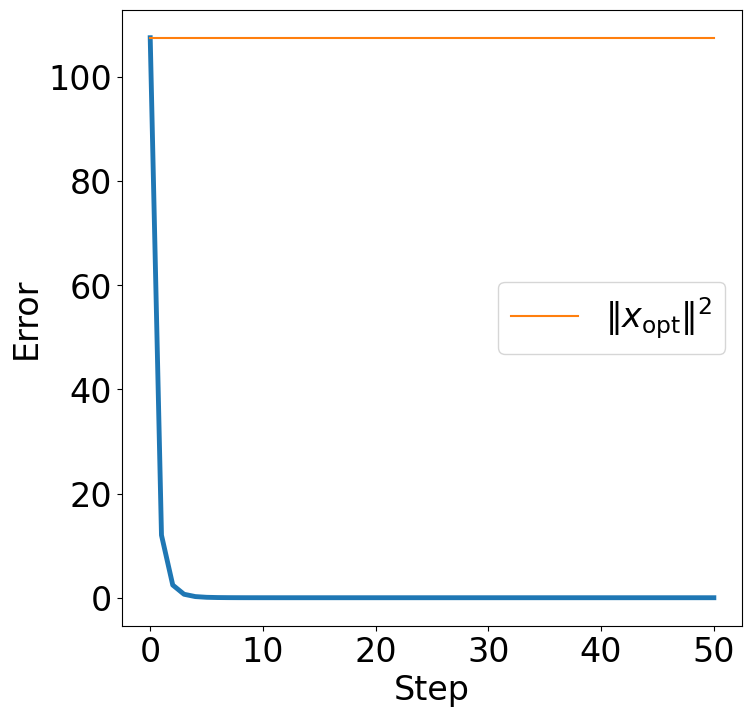

In [143]:
# x0 = 0 : tous les itérés restent dans l'image de A^T ; il n'y a aucune régularisation explicite.
# Le gradient utilisé est celui de l'objectif NON régularisé.
# La référence est la solution de norme minimale de CETTE instance (recalculée ici pour ne pas dépendre
# du x_opt d'une autre cellule) : x_mn = pinv(A) b.
x_mn = np.linalg.pinv(A).dot(b)

# We initialize from 0
x0 = np.zeros(n)
# Note this is the gradient w.r.t. the unregularized objective!
gradient = lambda x: least_squares_gradient(A, b, x)
xs = gradient_descent(x0, [0.1]*50, gradient)

plt.figure(figsize=(8, 8))
plt.xlabel('Step')
plt.ylabel('Error')
plt.plot(range(len(xs)), [np.linalg.norm(x_mn - x)**2 for x in xs], color='tab:blue', **kwargs)
plt.plot(range(len(xs)), [np.linalg.norm(x_mn)**2] * len(xs), color='tab:orange',
         label=r'$\|x_{\mathrm{opt}}\|^2$')
plt.legend()

*Incredible!* We converge to the minimum norm solution!

Implicit regularization is a deep phenomenon that's an active research topic in learning and optimization. It's exciting that we see it play out in this simple least squares problem already!

> **Ce que j'ai compris**
Ce n'est pas de la magie, c'est de l'algèbre linéaire. Les itérés ne quittent jamais x_0 + Im(Aᵀ). En partant de 0, ils restent dans Im(Aᵀ) (l'espace des lignes de A), et dans cet espace il n'y a qu'une seule solution qui ajuste les données : celle de norme minimale, pinv(A)b. La descente converge donc vers elle (notes EE227C: Implicit regularization »).

> **Interprétation:** Même algorithme et même problème que le cas sous-déterminé ; seule l'initialisation change (aléatoire → 0) et le résultat change de nature (plateau → convergence vers la solution de norme minimale).

> **Critique:** « Incredible! » est exagéré : le phénomène est exact pour les moindres carrés (modèle linéaire, gradient dans Im(Aᵀ)), mais sa généralisation à d'autres modèles est un sujet de recherche et ne doit pas être présentée comme acquise. De plus, la comparaison se fait avec le x_opt de la cellule ridge, qui est très proche de la solution de norme minimale (régularisation faible), et qui est légèrement faux (voir ci-dessus).

> L'initialisation peut jouer le rôle d'un régulariseur. Pour le LASSO, l'initialisation compte aussi, mais pour une autre raison

<a id="lasso"></a>
## LASSO

LASSO is the name for $\ell_1$-regularized least squares regression:

<p>
$$\frac1{2m}\|Ax-b\|^2 + \alpha\|x\|_1$$
</p>

We will see that LASSO is able to fine *sparse* solutions if they exist. This is a common motivation for using an $\ell_1$-regularizer.

> **Ce que j'ai compris de problème:** On cherche x ∈ ℝ¹⁰⁰⁰ qui minimise f(x) = (1/2m)‖Ax − b‖² + α‖x‖₁ avec seulement m = 100 équations (définition du LASSO : dans le , pdf p. 37 et 120). Les variables de décision sont les 1000 coefficients de x ; il n'y a pas de contrainte. Le terme de données g(x) = (1/2m)‖Ax − b‖² est convexe et lisse (L ≈ 17 ici, vérifié numériquement plus bas) mais pas fortement convexe, puisque m < n. Le terme α‖x‖₁ est convexe mais **non dérivable en 0**. Le problème est donc **convexe et non lisse** : tout minimum local est un minimum global.
> **Pourquoi ℓ1 ?** La pénalité ℓ1 favorise des solutions *parcimonieuses* (beaucoup de coordonnées exactement nulles), ce qui permet de sélectionner des variables quand il y a plus de variables que d'équations (slides de cours, p. 19-20).
> **Condition d'optimalité (hors cours).** x* est optimal si, pour chaque coordonnée i, ∇g(x*)ᵢ = −α·signe(xᵢ*) quand xᵢ* ≠ 0, et |∇g(x*)ᵢ| ≤ α quand xᵢ* = 0. C'est elle qui m'inspire le critère d'arrêt utilisé en E5.

In [144]:
# Fonctions du LASSO.
#  `lasso` appelle least_squares, qui utilise le m GLOBAL (voir la cellule des moindres carrés).
# alpha = 0.1 est répété par défaut dans trois fonctions ; changer α oblige à le changer partout.
# ell1_subgradient renvoie +1 en x = 0. C'est un sous-gradient valide (en 0, tout élément de [-1, 1] convient, cf. définition du sous-gradient dans le cours de Chrétien, pdf p. 147),
# mais np.sign(0) = 0 serait le choix de norme minimale. En pratique cela ne change rien ici, car les itérés ne valent presque jamais exactement 0.
def lasso(A, b, x, alpha=0.1):
    return least_squares(A, b, x) + alpha * np.linalg.norm(x, 1)

def ell1_subgradient(x):
    """Subgradient of the ell1-norm at x."""
    g = np.ones(x.shape)
    g[x < 0.] = -1.0
    return g

def lasso_subgradient(A, b, x, alpha=0.1):
    """Subgradient of the lasso objective at x"""
    return least_squares_gradient(A, b, x) + alpha*ell1_subgradient(x)

> La norme ℓ1 n'a pas de gradient en 0 ; on utilise donc un **sous-gradient** : signe(xᵢ) si xᵢ ≠ 0, et n'importe quelle valeur de [−1, 1] en 0 (définition du cours ). La méthode du sous-gradient remplace simplement le gradient par un sous-gradient dans la descente de gradient. Ce n'est **pas** une méthode de descente : l'objectif peut augmenter d'une itération à l'autre (je le vérifie plus bas).

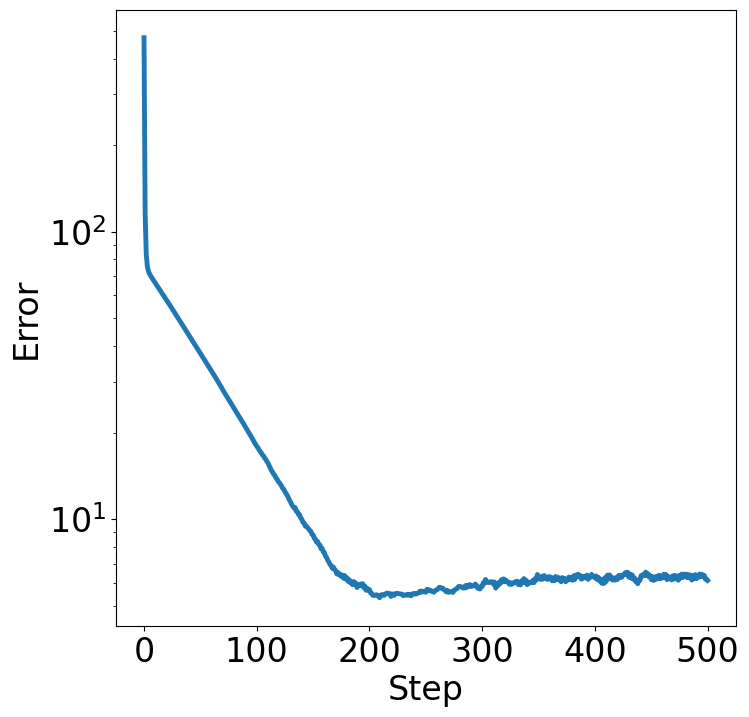

In [145]:
# Instance LASSO : x_opt = vrai paramètre 10-parcimonieux (10 premières coordonnées égales à 1), b = A x_opt SANS bruit, m = 100 < n = 1000.
# Sous-gradient avec pas constant 0.1, 500 itérations, départ aléatoire N(0,1).
# !!(a) m et n globaux sont redéfinis ici ; (b) aucune valeur optimale de référence n'est tracée ; (c) il n'y a aucun critère d'arrêt.
m, n = 100, 1000
A = np.random.normal(0, 1, (m, n))
x_opt = np.zeros(n)
x_opt[:10] = 1.0
b = A.dot(x_opt)
x0 = np.random.normal(0, 1, n)
xs = gradient_descent(x0, [0.1]*500, lambda x: lasso_subgradient(A, b, x))
error_plot([lasso(A, b, x) for x in xs])

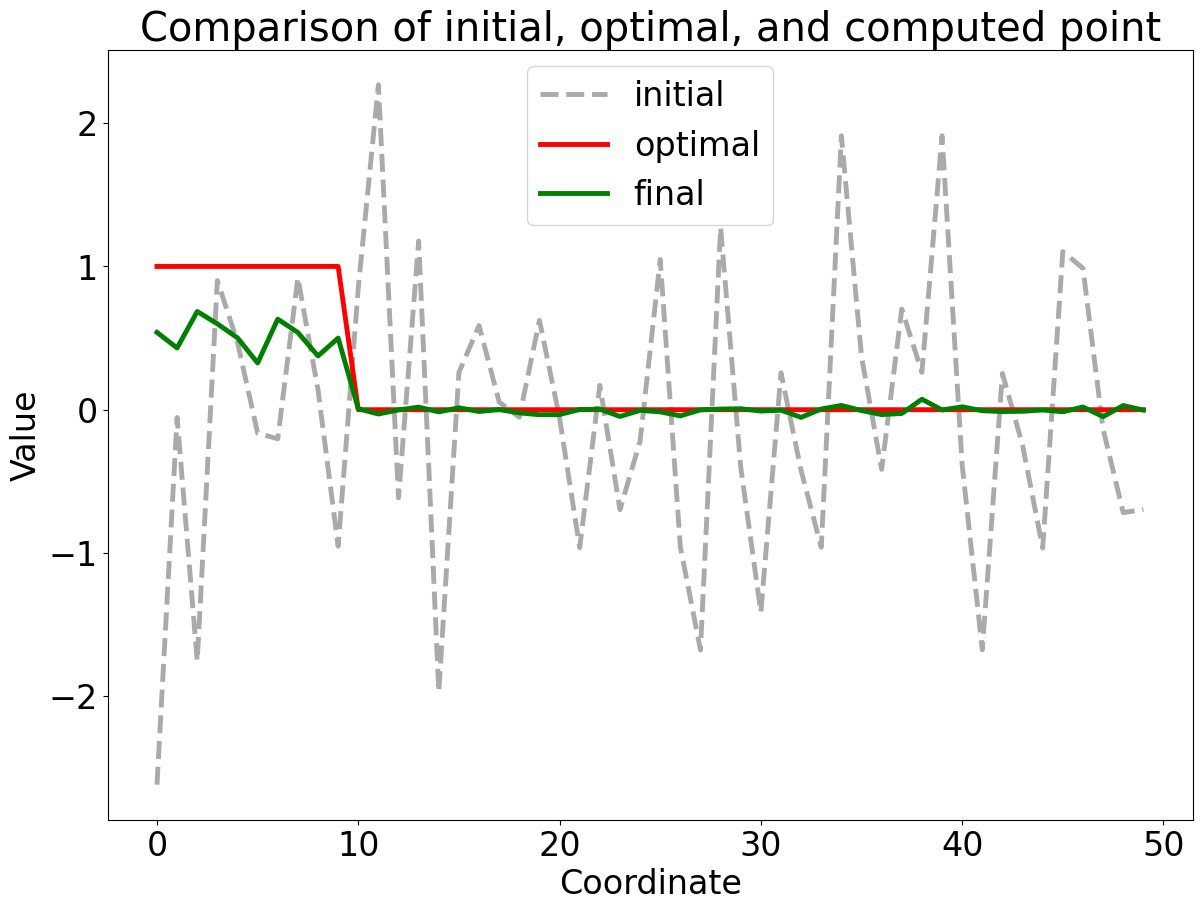

In [146]:
# Comparaison du point de départ (gris), du VRAI x_opt (rouge) et de l'itéré final (vert) sur les 50 premières coordonnées.
# !!le rouge est le vrai paramètre, pas la solution du LASSO, qui est biaisée vers 0 par la pénalité.
plt.figure(figsize=(14,10))
plt.title('Comparison of initial, optimal, and computed point')
idxs = range(50)
plt.plot(idxs, x0[idxs], '--', color='#aaaaaa', label='initial', **kwargs)
plt.plot(idxs, x_opt[idxs], 'r-', label='optimal', **kwargs)
plt.plot(idxs, xs[-1][idxs], 'g-', label='final', **kwargs)
plt.xlabel('Coordinate')
plt.ylabel('Value')
plt.legend()

As promised, LASSO correctly identifies the significant coordinates of the optimal solution. This is why, in practice, LASSO is a popular tool for feature selection.

Play around with this plot to inspect other points along the way, e.g., the point that achieves lowest objective value. Why does the objective value go up even though we continue to get better solutions?

###Ma boîte à outils pour les expériences
Cette cellule contient **mes** fonctions : sous-gradient complet, gradient stochastique par mini-batch, ISTA/FISTA et un générateur d'instances.
Elles utilisent un générateur aléatoire **local** (`default_rng`) pour ne pas changer la suite de nombres aléatoires du notebook d'origine.
Mon objectif s'appelle `lasso_obj` pour ne pas écraser la variable `objective` utilisée plus loin.

In [148]:

import numpy as np


def make_instance(seed, m=100, n=1000, k=10):
    """Instance du notebook: x_opt k-parcimonieux (k premieres coordonnees = 1), b = A x_opt (sans bruit)."""
    rng = np.random.default_rng(seed)
    A = rng.normal(0, 1, (m, n))
    x_true = np.zeros(n)
    x_true[:k] = 1.0
    b = A @ x_true
    return A, b, x_true, rng


def lasso_obj(A, b, x, alpha):
    m = A.shape[0]
    return 0.5 / m * np.sum((A @ x - b) ** 2) + alpha * np.sum(np.abs(x))


def grad_smooth(A, b, x):
    return A.T @ (A @ x - b) / A.shape[0]


def lipschitz(A):
    return np.linalg.norm(A, 2) ** 2 / A.shape[0]


def soft(x, t):
    return np.sign(x) * np.maximum(np.abs(x) - t, 0.0)


def subgradient_descent(A, b, alpha, x0, n_iter, step):
    """Sous-gradient complet. step: float (constant) ou callable k -> pas. sign(0)=0 (choix de sous-gradient)."""
    x = x0.copy()
    fs = [lasso_obj(A, b, x, alpha)]
    for k in range(n_iter):
        s = step(k) if callable(step) else step
        x = x - s * (grad_smooth(A, b, x) + alpha * np.sign(x))
        fs.append(lasso_obj(A, b, x, alpha))
    return x, np.array(fs)


def ista(A, b, alpha, x0, n_iter, step=None, accelerated=False):
    """ISTA / FISTA (gradient proximal). step par defaut 1/L."""
    L = lipschitz(A)
    s = 1.0 / L if step is None else step
    x = x0.copy()
    y = x.copy()
    t = 1.0
    fs = [lasso_obj(A, b, x, alpha)]
    for _ in range(n_iter):
        x_new = soft(y - s * grad_smooth(A, b, y), s * alpha)
        if accelerated:
            t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2
            y = x_new + (t - 1) / t_new * (x_new - x)
            t = t_new
        else:
            y = x_new
        x = x_new
        fs.append(lasso_obj(A, b, x, alpha))
    return x, np.array(fs)


def sgd(A, b, alpha, x0, n_epochs, batch, step, rng, prox=False, record_every_epoch=True):
    """Gradient stochastique par mini-batch (tirage sans remise a chaque iteration).
    Une 'epoque' = m/batch iterations (m evaluations de gradients de ligne).
    prox=False : sous-gradient stochastique ; prox=True : gradient proximal stochastique.
    Renvoie x final et la liste f(x) a la fin de chaque epoque (budget de calcul commun)."""
    m, n = A.shape
    x = x0.copy()
    iters_per_epoch = max(m // batch, 1)
    fs = [lasso_obj(A, b, x, alpha)]
    k = 0
    for _ in range(n_epochs):
        for _ in range(iters_per_epoch):
            idx = rng.choice(m, size=batch, replace=False) if batch < m else slice(None)
            Ab, bb = A[idx], b[idx]
            g = Ab.T @ (Ab @ x - bb) / batch
            s = step(k) if callable(step) else step
            if prox:
                x = soft(x - s * g, s * alpha)
            else:
                x = x - s * (g + alpha * np.sign(x))
            k += 1
        fs.append(lasso_obj(A, b, x, alpha))
    return x, np.array(fs)


def support_metrics(x, x_true, tol=1e-3):
    """Support estime = {|x_i|>tol}. Renvoie (nb de coordonnees non nulles, F1 du support, erreur relative)."""
    est = np.abs(x) > tol
    true = x_true != 0
    tp = np.sum(est & true)
    prec = tp / max(est.sum(), 1)
    rec = tp / max(true.sum(), 1)
    f1 = 0.0 if tp == 0 else 2 * prec * rec / (prec + rec)
    return int(est.sum()), float(f1), float(np.linalg.norm(x - x_true) / np.linalg.norm(x_true))


# Imports supplémentaires pour les expériences (tableaux, comparaison avec scikit-learn)
import time
import pandas as pd
from sklearn.linear_model import Lasso as SkLasso

f* (FISTA) = 0.951 ; f(x_0) = 472.8 ; min_k f(x_k) = 5.324 atteint a k = 209 ; f(x_500) = 6.117
k=209 | f-f* =  4.372 | terme de donnees = 2.643 | alpha*||x||_1 = 2.681 | ||x_k - x*|| = 2.714
k=300 | f-f* =  4.875 | terme de donnees = 3.502 | alpha*||x||_1 = 2.325 | ||x_k - x*|| = 1.742
k=400 | f-f* =  5.288 | terme de donnees = 3.879 | alpha*||x||_1 = 2.360 | ||x_k - x*|| = 1.562
k=500 | f-f* =  5.165 | terme de donnees = 3.765 | alpha*||x||_1 = 2.351 | ||x_k - x*|| = 1.509
support de x* (|x_i|>1e-3) : 10 coordonnees ; f* = 0.951


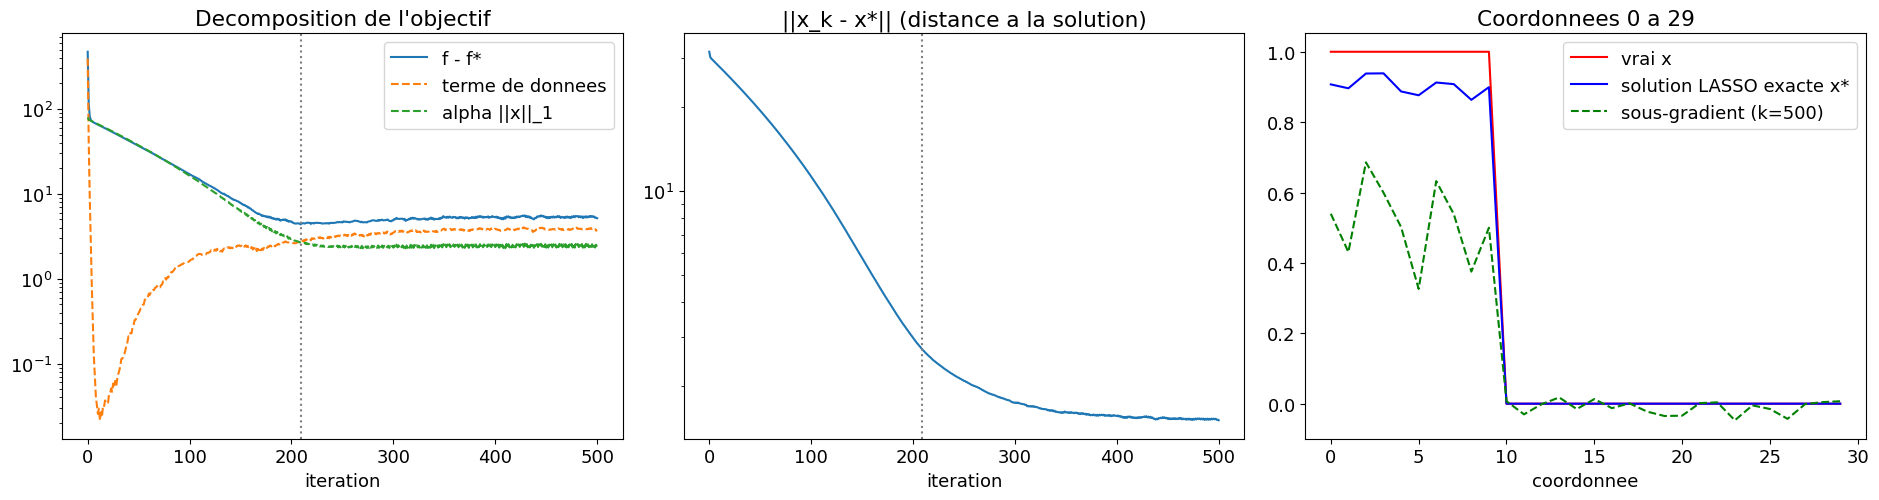

In [149]:
# Diagnostic : que se passe-t-il vraiment pendant les 500 itérations du notebook ?
alpha_ = 0.1
x_star, f_hist = ista(A, b, alpha_, np.zeros(n), 20000, accelerated=True)   # solution "exacte" par FISTA
f_star = f_hist[-1]
F      = np.array([lasso(A, b, x) for x in xs])                              # objectif total
smooth = np.array([least_squares(A, b, x) for x in xs])                      # terme de donnees
l1pen  = np.array([alpha_ * np.linalg.norm(x, 1) for x in xs])               # penalite
dist   = np.array([np.linalg.norm(x - x_star) for x in xs])                  # distance a la solution du LASSO
kmin = int(F.argmin())
print("f* (FISTA) = %.3f ; f(x_0) = %.1f ; min_k f(x_k) = %.3f atteint a k = %d ; f(x_500) = %.3f" % (f_star, F[0], F.min(), kmin, F[-1]))
for k in [kmin, 300, 400, 500]:
    print("k=%3d | f-f* = %6.3f | terme de donnees = %.3f | alpha*||x||_1 = %.3f | ||x_k - x*|| = %.3f" % (k, F[k] - f_star, smooth[k], l1pen[k], dist[k]))
print("support de x* (|x_i|>1e-3) : %d coordonnees ; f* = %.3f" % (np.sum(np.abs(x_star) > 1e-3), f_star))
with plt.rc_context({'font.size': 13}):
    fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
    ax[0].plot(F - f_star, label='f - f*'); ax[0].plot(smooth, '--', label='terme de donnees'); ax[0].plot(l1pen, '--', label='alpha ||x||_1')
    ax[0].axvline(kmin, color='gray', ls=':'); ax[0].set_yscale('log'); ax[0].set_xlabel('iteration'); ax[0].set_title('Decomposition de l\'objectif'); ax[0].legend()
    ax[1].plot(dist); ax[1].axvline(kmin, color='gray', ls=':'); ax[1].set_yscale('log'); ax[1].set_xlabel('iteration'); ax[1].set_title('||x_k - x*|| (distance a la solution)')
    idx = range(30)
    ax[2].plot(idx, x_opt[list(idx)], 'r-', label='vrai x'); ax[2].plot(idx, x_star[list(idx)], 'b-', label='solution LASSO exacte x*'); ax[2].plot(idx, xs[-1][list(idx)], 'g--', label='sous-gradient (k=500)')
    ax[2].set_xlabel('coordonnee'); ax[2].set_title('Coordonnees 0 a 29'); ax[2].legend()
    plt.tight_layout(); plt.show()

> **Interprétation de la figure du notebook:**
 L'objectif chute d'environ 470 à environ 6, puis **plafonne et remonte légèrement**. Pour cette instance, l'optimum exact vaut f* ≈ 0,95 : l'objectif final est donc plus de 5 fois trop grand, et l'algorithme **n'a pas convergé**. Le graphique en échelle log ne le montre pas, parce qu'aucune valeur optimale n'y est tracée (critique).

> **Réponse à la question du notebook** (« pourquoi l'objectif remonte alors que les solutions s'améliorent ? »). La cellule de diagnostic le mesure : après le minimum de l'objectif, la distance ‖x_k − x*‖ continue de **diminuer**, alors que le **terme de données augmente**. La figure de gauche en donne l'origine : le terme de données s'effondre vers 0,02 dès les ≈ 10 premières itérations (l'itéré ajuste presque exactement les données), puis il remonte à mesure que la pénalité ℓ1 ramène les 990 autres coordonnées vers 0. C'est le compromis normal entre ajustement des données et parcimonie, pas une erreur de calcul. Une meilleure valeur de l'objectif ne signifie donc pas forcément un meilleur point, et réciproquement.

> **Pourquoi l'objectif plafonne-t-il ?** Il y a deux explications, dont la première est observée et la seconde est une hypothèse. (1) Avec un pas constant s, chaque coordonnée oscille autour de 0 avec une amplitude de l'ordre de s·α, parce que le sous-gradient signe(x) change brutalement de signe : l'algorithme ne se stabilise pas. (2) Hypothèse, cohérente avec les chiffres de E1 mais non testée seule : le pas 0,1 est compris entre 1/L ≈ 0,059 et 2/L ≈ 0,117, ce qui amplifie les oscillations dans les directions les plus raides.

> **Sur la figure des coordonnées:** Le rouge est le vrai x, pas la solution du LASSO. Le LASSO exact x* (bleu) est lui-même **biaisé vers 0** par la pénalité (≈ 0,9 sur le support au lieu de 1), et l'itéré du sous-gradient en est encore plus éloigné (≈ 0,3 à 0,7) : comparer avec le vrai x est donc trompeur. Sur l'instance du notebook, x* a exactement 10 coordonnées non nulles ; ce n'est pas général : sur mes 10 instances la médiane est de 13 (voir E4). Le résultat « le LASSO identifie les bonnes coordonnées » est donc vrai pour x*, aux faux positifs près ; l'itéré du sous-gradient, lui, n'est pas parcimonieux au sens strict (il n'a pas de zéros exacts).
>  Avec un pas constant, le sous-gradient fait vite baisser l'objectif puis il stagne : on ne peut pas se fier à la courbe seule, il faut comparer à une solution de référence.

---
# Partie ajoutée : expériences sur l'optimisation du LASSO (E1 à E5)
**Cadre.** Même problème que ci-dessus (m = 100, n = 1000, 10 coordonnées non nulles égales à 1, α = 0,1, sans bruit). Chaque expérience utilise plusieurs instances aléatoires indépendantes et je donne la **médiane** (graines 0 à 9, sauf E3 : 0 à 4). Les graines sont fixées, donc les résultats sont reproductibles.

**Solution de référence.** Je calcule f* avec FISTA (30 000 itérations), puis je **vérifie** le résultat avec scikit-learn, qui minimise exactement la même fonction.

In [150]:
#Réglages communs ; les figures de cette partie utilisent une police plus petite (je restaure l'ancienne à la fin de la partie)
ALPHA = 0.1
SEEDS = list(range(10))
OLD_RC = {k: plt.rcParams[k] for k in ['font.size', 'axes.grid', 'grid.alpha']}
plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': .3})

# Je crée 10 instances (A, b, vrai x, point de départ) et calcule pour chacune son optimum exact f*.
# Les noms A_i, b_i... évitent d'écraser les variables A et b du notebook d'origine.
instances = []
for sd in SEEDS:
    A_i, b_i, xt_i, rng_i = make_instance(sd)
    xs_i, fs_i = ista(A_i, b_i, ALPHA, np.zeros(A_i.shape[1]), 30000, accelerated=True)
    instances.append(dict(A=A_i, b=b_i, xt=xt_i, x0=rng_i.normal(0, 1, A_i.shape[1]), xstar=xs_i, fstar=fs_i[-1], L=lipschitz(A_i)))
I0 = instances[0]
sk = SkLasso(alpha=ALPHA, fit_intercept=False, tol=1e-12, max_iter=200000).fit(I0['A'], I0['b'])
print("L moyen = %.2f  ->  1/L = %.4f, 2/L = %.4f" % (np.mean([i['L'] for i in instances]), 1 / np.mean([i['L'] for i in instances]), 2 / np.mean([i['L'] for i in instances])))
print("f* (FISTA) = %.8f   f* (scikit-learn) = %.8f   ||x_FISTA - x_sklearn|| = %.1e" % (I0['fstar'], lasso_obj(I0['A'], I0['b'], sk.coef_, ALPHA), np.linalg.norm(I0['xstar'] - sk.coef_)))
nnz0, f10, _ = support_metrics(I0['xstar'], I0['xt'])
print("Solution LASSO exacte : %d coordonnees non nulles (|x_i| > 1e-3) pour 10 vraies ; F1 du support = %.2f" % (nnz0, f10))

L moyen = 17.06  ->  1/L = 0.0586, 2/L = 0.1173
f* (FISTA) = 0.95543899   f* (scikit-learn) = 0.95543899   ||x_FISTA - x_sklearn|| = 7.2e-13
Solution LASSO exacte : 13 coordonnees non nulles (|x_i| > 1e-3) pour 10 vraies ; F1 du support = 0.87


> **Ce que j'ai compris:** La solution de référence est la même fonction minimisée par deux codes indépendants (le mien et scikit-learn) : s'ils donnent le même point à 10⁻¹² près, l'objectif et le gradient que j'ai programmés sont corrects. C'est une **vérification de mon implémentation**, indispensable avant d'interpréter des courbes.

> **Interprétation.** Même avec la solution exacte, le LASSO sélectionne plus de coordonnées que les 10 vraies (F1 < 1) : c'est une propriété du modèle avec α fixé, pas un défaut du solveur.

## E1. Effet du pas sur le sous-gradient (gradient complet)
**Paramètre modifié :** le pas s, constant (0,2 ; 0,1 comme dans le notebook ; 0,05 ; 0,01 ; 0,001) ou décroissant s₀/√(k+1) (s₀ = 0,1 et 0,05). Les valeurs sont choisies autour de 1/L ≈ 0,059 et 2/L ≈ 0,117 (au-delà de 2/L, le terme lisse diverge ; notes EE227C, ch. 2).

**Ce qui reste constant :** les instances, le point de départ, 3000 itérations.

**Métrique :** f(x_k) − f* (médiane sur 10 instances, et maximum), et nombre de coordonnées non nulles.

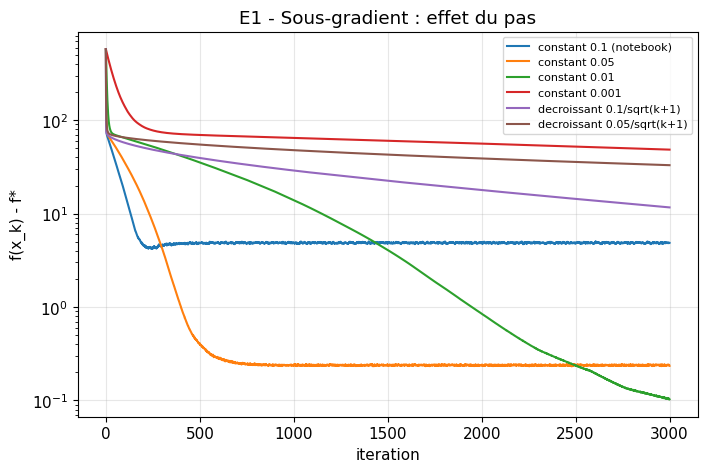

,subopt_finale_mediane,subopt_finale_max,nnz_mediane
pas,,,
constant 0.2 (> 2/L),NaN,NaN,0.0
constant 0.1 (notebook),4.870901,6.814781,945.5
constant 0.05,0.234731,0.258378,807.0
constant 0.01,0.103143,0.172469,218.5
constant 0.001,48.415975,51.937752,774.0
decroissant 0.1/sqrt(k+1),11.658034,14.032790,326.0
decroissant 0.05/sqrt(k+1),33.001734,36.022335,597.0


In [151]:
# Chaque pas est testé sur les 10 mêmes instances ; on trace la médiane de f(x_k) - f*.
cfg = {'constant 0.2 (> 2/L)': 0.2, 'constant 0.1 (notebook)': 0.1, 'constant 0.05': 0.05, 'constant 0.01': 0.01,
       'constant 0.001': 0.001, 'decroissant 0.1/sqrt(k+1)': (lambda k: 0.1 / np.sqrt(k + 1)), 'decroissant 0.05/sqrt(k+1)': (lambda k: 0.05 / np.sqrt(k + 1))}
rows = []
plt.figure(figsize=(8, 5))
with np.errstate(all='ignore'):                       # le pas 0.2 diverge : on masque les avertissements de depassement
    for name, st in cfg.items():
        C_, nn = [], []
        for I in instances:
            x, fs = subgradient_descent(I['A'], I['b'], ALPHA, I['x0'], 3000, st)
            C_.append(np.maximum(fs - I['fstar'], 1e-16)); nn.append(support_metrics(x, I['xt'])[0])
        C_ = np.array(C_)
        rows.append(dict(pas=name, subopt_finale_mediane=np.median(C_[:, -1]), subopt_finale_max=np.max(C_[:, -1]), nnz_mediane=np.median(nn)))
        if np.all(np.isfinite(C_)): plt.plot(np.median(C_, axis=0), label=name)
plt.yscale('log'); plt.xlabel('iteration'); plt.ylabel('f(x_k) - f*'); plt.title('E1 - Sous-gradient : effet du pas'); plt.legend(fontsize=8); plt.show()
pd.DataFrame(rows).set_index('pas')

> **Résultats mesurés**
(médiane sur 10 instances, 3000 itérations, f − f*). Pas 0,2 : **diverge**. Pas 0,1 (celui du notebook) : **4,9** (plateau). Pas 0,05 : **0,23**. Pas 0,01 : **0,10**. Pas 0,001 : **48**. Décroissant 0,1/√(k+1) : 11,7 ; 0,05/√(k+1) : 33.

> **Interprétation.** Le pas joue **deux rôles opposés**. Trop grand, l'algorithme oscille et plafonne (0,1) ou diverge (0,2). Trop petit, il est trop lent : dans le noyau de A, chaque coordonnée ne diminue que de s·α par itération, donc avec s = 0,001 le déplacement total est 3000 × 0,001 × 0,1 = 0,3, alors que les coordonnées de départ valent environ ±1 (résultat : 48). Avec s = 0,01, le déplacement total est 3, ce qui suffit pour la plupart des coordonnées : c'est le meilleur résultat (0,10), mais ce **n'est pas** la convergence, il reste environ 10 % de l'objectif optimal.

> **Pas décroissant.** Le déplacement total ∑ s_k vaut environ 0,2·√3000 ≈ 11 pour 0,1/√(k+1), soit α·∑ s_k ≈ 1,1 par coordonnée : c'est trop peu pour ramener à 0 les coordonnées de départ plus grandes que 1,1. Le cours donne, pour une fonction convexe et Lipschitz, un pas en R/(L√t) et une vitesse en RL/√t : cette vitesse en 1/√t est très lente, ce qui est cohérent avec ce que je mesure (3000 itérations ne suffisent pas). Ce théorème est énoncé pour le gradient, son extension au sous-gradient est un résultat standard .

> **Ce que j'en conclus.**
 Aucun pas ne donne à la fois précision et vitesse : c'est la limite de la méthode du sous-gradient, et c'est ce qui motive l'alternative proximale
 (E2).

  **Limites de l'expérience :** une grille de pas courte, un seul schéma décroissant, 3000 itérations ; je ne prétends pas qu'aucun autre réglage ne ferait mieux.
  
> Le pas est un compromis entre stabilité (pas trop grand) et vitesse (pas trop petit), et pour le sous-gradient aucune valeur ne résout les deux.

## E2. Sous-gradient contre méthode proximale (ISTA / FISTA)
**Idée:** ISTA remplace le sous-gradient de α‖x‖₁ par son **opérateur proximal**, le seuillage doux : x_{k+1} = soft(x_k − ∇g(x_k)/L, α/L). C'est la méthode adaptée à « lisse + ℓ1 » : le cours l'appelle gradient proximal pour fonctions composites (pdf p. 120-123) et donne le cas du LASSO avec le seuillage doux (pdf p. 132). Comme on l'a noté pour le gradient projeté, la formule ressemble à celle du cours, avec le prox à la place de la projection. FISTA ajoute l'extrapolation de Nesterov (notes EE227C, ch. 8).

**Ce qui reste constant :** les instances, le départ, 1500 itérations.

**Métriques :** f − f*, **résidu proximal** (nul si et seulement si x est optimal), nombre de coordonnées non nulles, F1 du support, itérations pour atteindre 10⁻³ et 10⁻⁶.

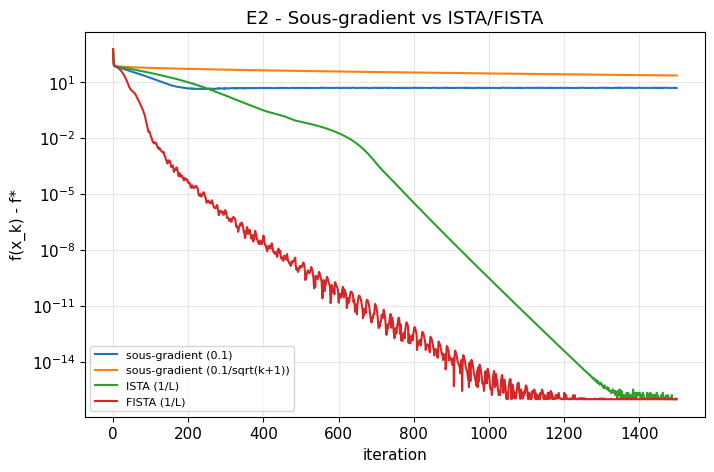

,subopt_finale,residu_proximal,nnz,F1_support,it_pour_1e_3,it_pour_1e_6
methode,,,,,,
sous-gradient (0.1),4.784490e+00,1.095859e+01,947.5,0.020888,jamais,jamais
sous-gradient (0.1/sqrt(k+1)),2.249100e+01,2.035202e+00,468.5,0.017171,jamais,jamais
ISTA (1/L),1.000000e-16,1.858524e-10,13.0,0.869565,681.0,826.5
FISTA (1/L),1.000000e-16,8.264510e-11,13.0,0.869565,127.0,255.0


In [152]:
def prox_residual(A_, b_, x, alpha, L):
    # Résidu proximal L*||x - soft(x - grad g(x)/L, alpha/L)|| : il s'annule exactement aux points optimaux, donc il sert de critère d'arrêt.
    return L * np.linalg.norm(x - soft(x - grad_smooth(A_, b_, x) / L, alpha / L))

names = ['sous-gradient (0.1)', 'sous-gradient (0.1/sqrt(k+1))', 'ISTA (1/L)', 'FISTA (1/L)']
store = {k: dict(C=[], res=[], nnz=[], f1=[], it3=[], it6=[]) for k in names}
for I in instances:
    runs = {names[0]: subgradient_descent(I['A'], I['b'], ALPHA, I['x0'], 1500, 0.1),
            names[1]: subgradient_descent(I['A'], I['b'], ALPHA, I['x0'], 1500, lambda k: 0.1 / np.sqrt(k + 1)),
            names[2]: ista(I['A'], I['b'], ALPHA, I['x0'], 1500),
            names[3]: ista(I['A'], I['b'], ALPHA, I['x0'], 1500, accelerated=True)}
    for k, (x, fs) in runs.items():
        sub = np.maximum(fs - I['fstar'], 1e-16); s = store[k]
        s['C'].append(sub); s['res'].append(prox_residual(I['A'], I['b'], x, ALPHA, I['L']))
        nn, f1, _ = support_metrics(x, I['xt']); s['nnz'].append(nn); s['f1'].append(f1)
        for tol, key in [(1e-3, 'it3'), (1e-6, 'it6')]:
            idx = np.where(sub < tol)[0]; s[key].append(idx[0] if len(idx) else np.nan)
plt.figure(figsize=(8, 5)); rows = []
for k in names:
    C_ = np.array(store[k]['C']); plt.plot(np.median(C_, axis=0), label=k)
    never = lambda key: 'jamais' if np.all(np.isnan(store[k][key])) else np.nanmedian(store[k][key])
    rows.append(dict(methode=k, subopt_finale=np.median(C_[:, -1]), residu_proximal=np.median(store[k]['res']), nnz=np.median(store[k]['nnz']),
                     F1_support=np.median(store[k]['f1']), it_pour_1e_3=never('it3'), it_pour_1e_6=never('it6')))
plt.yscale('log'); plt.xlabel('iteration'); plt.ylabel('f(x_k) - f*'); plt.title('E2 - Sous-gradient vs ISTA/FISTA'); plt.legend(fontsize=8); plt.show()
pd.DataFrame(rows).set_index('methode')

> **Résultats mesurés:** (médiane sur 10 instances). ISTA et FISTA atteignent f − f* ≈ 10⁻¹⁶ (précision machine), un résidu proximal ≈ 10⁻¹⁰ et **13 coordonnées non nulles** (F1 du support 0,87). ISTA atteint 10⁻³ en ≈ 680 itérations et 10⁻⁶ en ≈ 830 ; FISTA en ≈ 127 et ≈ 255. Les sous-gradients (pas 0,1 et 0,1/√(k+1)) n'atteignent **jamais** 10⁻³ et gardent des centaines de coordonnées non nulles (le seuil 10⁻³ est plus petit que l'amplitude de leurs oscillations).


> **Interprétation:** L'opérateur proximal traite exactement la partie non lisse : il produit de **vrais zéros**, et le point fixe de l'itération est exactement la solution du LASSO. Le sous-gradient, lui, ne peut pas s'y fixer, car son pas ne s'annule pas et le signe oscille. Sur la courbe, ISTA a d'abord une phase lente puis une décroissance linéaire (une droite en échelle log). Une explication connue est qu'une fois le support identifié, le problème devient localement fortement convexe (hors cours, non testé ici). FISTA accélère nettement (127 contre 680 itérations), comme le laisse prévoir l'accélération de Nesterov du cours (notes EE227C, ch. 8), mais il n'est pas monotone : on voit de petites oscillations sur la courbe.


> **Critique:** Je compare à **nombre d'itérations** égal et non à coût égal ; ici une itération de chaque méthode coûte un produit matrice-vecteur pour le gradient, donc les coûts sont comparables. Les performances d'ISTA/FISTA supposent de connaître L : je le calcule exactement par une SVD, ce qui est coûteux pour de très grandes matrices (on peut l'estimer ou faire une recherche linéaire, hors cours).
>  Pour « lisse + ℓ1 », il vaut mieux traiter la partie ℓ1 par son opérateur proximal plutôt que par un sous-gradient : on gagne la convergence, de vrais zéros et un critère d'arrêt.

## E3. Taille du mini-batch (gradient stochastique)
**Idée:** (slides p. 24-26 ; notes EE227C, ch. 10). Au lieu du gradient complet (m lignes), on utilise un mini-batch de b lignes tirées au hasard : une itération coûte b/m du gradient complet, mais le gradient est **bruité**.

**Paramètre modifié :** b ∈ {1, 5, 10, 25, 50, 100} (b = 100 = m correspond au gradient complet).

**Budget identique :** 1000 *époques* (une époque = m lignes évaluées). Le pas vaut c/L_b avec L_b ≈ (√n + √b)²/b (valeur propre maximale typique de (1/b)A_BᵀA_B pour une matrice gaussienne : **c'est mon estimation, pas un résultat du cours**) et c ∈ {0,1 ; 0,3 ; 0,9}. Deux variantes : sous-gradient stochastique et gradient proximal stochastique (cours p. 124-125). 5 instances, médiane. *

*Métriques :** f − f* finale et temps de calcul.

duree E3 : 379 s


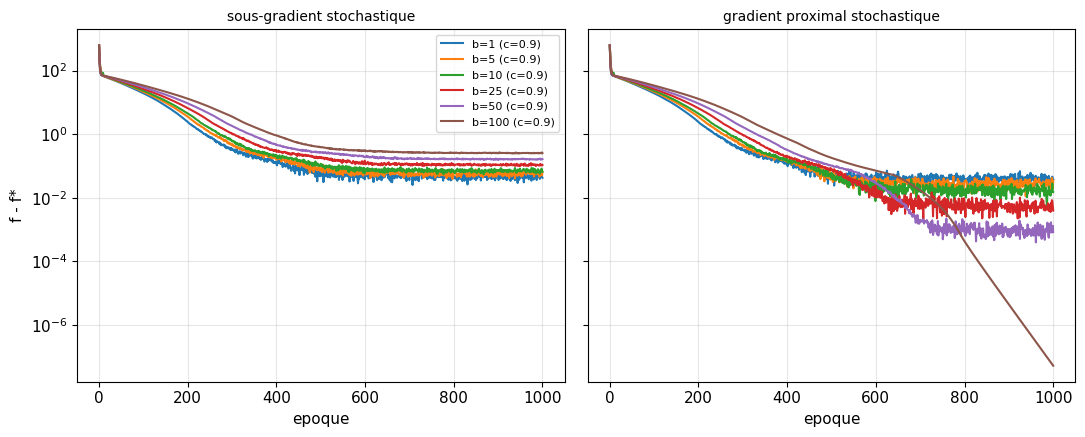

c                                         0.1       0.3           0.9
variante                       b                                     
gradient proximal stochastique 1    16.160113  0.149290  3.734851e-02
                               5    18.372307  0.224569  3.452759e-02
                               10   19.994618  0.277249  1.499134e-02
                               25   23.143687  0.510097  3.948607e-03
                               50   26.508584  0.949791  8.364954e-04
                               100  30.615962  1.923318  5.243982e-08
sous-gradient stochastique     1    16.160625  0.151542  4.241492e-02
                               5    18.374415  0.233278  6.548746e-02
                               10   19.998102  0.292997  6.570544e-02
                               25   23.149130  0.539349  1.072763e-01
                               50   26.517354  0.988072  1.638704e-01
                               100  30.628204  1.976760  2.541300e-01

In [153]:
# Pour chaque variante, taille de batch b et constante c, on lance 1000 époques sur 5 instances (budget de calcul identique).
EPOCHS, BATCHES, CS = 1000, [1, 5, 10, 25, 50, 100], [0.1, 0.3, 0.9]
insts3 = instances[:5]
def Lb(bsz): return (np.sqrt(1000) + np.sqrt(bsz)) ** 2 / bsz if bsz < 100 else np.mean([i['L'] for i in insts3])
rows, curves = [], {}
t_start = time.time()
for variant, prox in [('sous-gradient stochastique', False), ('gradient proximal stochastique', True)]:
    for bsz in BATCHES:
        for c in CS:
            s = c / Lb(bsz); fin, tm, cur = [], [], []
            for I in insts3:
                rng = np.random.default_rng(77 + bsz); t = time.time()
                x, fs = sgd(I['A'], I['b'], ALPHA, I['x0'], EPOCHS, bsz, s, rng, prox=prox)
                tm.append(time.time() - t); sub = np.maximum(fs - I['fstar'], 1e-16); fin.append(sub[-1]); cur.append(sub)
            rows.append(dict(variante=variant, b=bsz, c=c, pas=s, subopt_mediane=np.median(fin), subopt_max=np.max(fin), temps_s=np.mean(tm)))
            curves[(variant, bsz, c)] = np.median(np.array(cur), axis=0)
df3 = pd.DataFrame(rows)
print("duree E3 : %.0f s" % (time.time() - t_start))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, variant in zip(axes, ['sous-gradient stochastique', 'gradient proximal stochastique']):
    for bsz in BATCHES:
        sub_ = df3[(df3.variante == variant) & (df3.b == bsz)]; cbest = sub_.loc[sub_.subopt_mediane.idxmin(), 'c']
        ax.plot(curves[(variant, bsz, cbest)], label='b=%d (c=%.1f)' % (bsz, cbest))
    ax.set_yscale('log'); ax.set_xlabel('epoque'); ax.set_title(variant, fontsize=10)
axes[0].set_ylabel('f - f*'); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()
df3.pivot_table(index=['variante', 'b'], columns='c', values='subopt_mediane')

In [154]:
df3[df3.c == 0.9].set_index(['variante', 'b'])[['pas', 'subopt_mediane', 'temps_s']]

pas  subopt_mediane   temps_s
variante                       b                                      
sous-gradient stochastique     1    0.000846    4.241492e-02  9.879592
                               5    0.003925    6.548746e-02  3.292088
                               10   0.007438    6.570544e-02  1.333323
                               25   0.016776    1.072763e-01  0.349205
                               50   0.030056    1.638704e-01  0.336372
                               100  0.052565    2.541300e-01  0.144079
gradient proximal stochastique 1    0.000846    3.734851e-02  8.337200
                               5    0.003925    3.452759e-02  1.119131
                               10   0.007438    1.499134e-02  0.663951
                               25   0.016776    3.948607e-03  0.516959
                               50   0.030056    8.364954e-04  0.277580
                               100  0.052565    5.243982e-08  0.118810

> **Résultats mesurés:** (médiane sur 5 instances, 1000 époques, c = 0,9). *Gradient proximal stochastique* : f − f* vaut ≈ 3,7·10⁻² pour b = 1, 1,5·10⁻² pour b = 10, 8·10⁻⁴ pour b = 50 et **5·10⁻⁸ pour b = 100** (gradient complet). *Sous-gradient stochastique* : toutes les tailles restent entre 4·10⁻² et 0,25. **Temps :** ≈ 2,3 s pour b = 1, ≈ 0,05 s pour b = 100.

> **Interprétation:** À budget de données égal, **la plus grande taille de batch est la meilleure** pour la variante proximale. Pour b petit, le bruit du gradient impose un pas plus petit (le pas stable est proportionnel à 1/L_b, qui vaut environ 1000 pour b = 1 contre 17 pour b = 100) et laisse un plancher d'erreur. La raison est que la solution du LASSO n'ajuste pas exactement les données (le vrai x n'est pas son minimiseur, à cause du biais de la pénalité) : les gradients par ligne ne s'annulent donc pas à l'optimum, et le bruit ne disparaît pas. Cela ressemble à la formule du cours page 118 pour le cas fortement convexe : avec un pas constant s, l'erreur ne descend pas sous un plancher proportionnel à s·σ²/α (σ² étant la variance du gradient stochastique). Mon cas n'est pas fortement convexe, donc je ne l'utilise que comme analogie. Pour le sous-gradient stochastique, tout reste entre 4·10⁻² et 0,25 : les deux effets (oscillation du signe et bruit) s'ajoutent et je ne vois plus de lien net avec b.

> **Critique et limites.** (1) m = 100 est **minuscule** : le gradient complet coûte presque rien, donc le gradient stochastique n'a aucun avantage ici. Ce résultat ne dit rien sur le cas pour lequel il a été conçu (m très grand). (2) Le temps pour b = 1 est dominé par la boucle Python, pas par le calcul. (3) Le meilleur c (0,9) est au **bord de ma grille** : un pas un peu plus grand serait peut-être meilleur. (4) Je n'ai que 5 instances. (5) Je n'ai pas testé de pas décroissant ni de méthode à variance réduite (SVRG, SAGA ), qui sont les remèdes habituels au plancher de bruit.

>* Le mini-batch réduit le coût par itération mais introduit du bruit ; il n'est utile que lorsque le gradient complet est trop cher, ce qui n'est pas le cas avec m = 100.

## E4. Paramètre de régularisation α
**Paramètre modifié :** α ∈ {0,01 ; 0,03 ; 0,1 ; 0,3 ; 1}. **Ce qui reste constant :** la solution exacte (FISTA, 20 000 itérations, départ 0) et 10 instances.

**Métriques :** nombre de coordonnées non nulles, F1 du support, erreur relative ‖x − x_vrai‖/‖x_vrai‖.

In [155]:
# Pour chaque α, solution exacte par FISTA sur les 10 instances, puis mesures sur le support et l'erreur.
rows = []
for alpha in [0.01, 0.03, 0.1, 0.3, 1.0]:
    f1s, nn, er = [], [], []
    for I in instances:
        x, _ = ista(I['A'], I['b'], alpha, np.zeros(1000), 20000, accelerated=True)
        a_, f1_, e_ = support_metrics(x, I['xt']); nn.append(a_); f1s.append(f1_); er.append(e_)
    rows.append(dict(alpha=alpha, nnz_mediane=np.median(nn), F1_support=np.median(f1s), erreur_relative=np.median(er)))
pd.DataFrame(rows).set_index('alpha')

,nnz_mediane,F1_support,erreur_relative
alpha,,,
0.01,11.0,0.952381,0.011898
0.03,12.0,0.909091,0.035695
0.10,13.0,0.869565,0.118984
0.30,13.0,0.869565,0.356952
1.00,4.5,0.598214,0.909005


> **Résultats mesurés:** α = 0,01 : 11 coordonnées non nulles, F1 = 0,95, erreur relative 1 %. α = 0,1 : 13 non nulles, F1 = 0,87, erreur 12 %. α = 0,3 : 13, F1 = 0,87, erreur 36 %. α = 1 : 4,5 non nulles, F1 = 0,60, erreur 91 %.

> **Interprétation:** α règle un compromis **biais / parcimonie** : plus α est grand, plus la solution est parcimonieuse, mais plus elle est **biaisée vers 0** (l'erreur relative croît presque proportionnellement à α entre 0,01 et 0,3), jusqu'à perdre de vraies coordonnées (α = 1). Le « meilleur » α dépend de l'objectif (identifier le support ou estimer les valeurs). Ici je connais la vérité, ce qui n'est pas le cas en pratique : on choisirait α par validation croisée .

> **Limite:** Mes données sont sans bruit et la matrice est gaussienne : c'est un cadre favorable. Je n'ai pas testé le comportement avec du bruit ou des colonnes corrélées.
>  α n'est pas un réglage numérique mais un choix de modèle : il fixe le compromis entre parcimonie et biais.

## E5. Initialisation et critère d'arrêt
**(a) Initialisation:** x₀ = 0 contre x₀ ~ N(0, I) (comme dans le notebook), 1000 itérations, 10 instances.

**(b) Critère d'arrêt:** Je compare, le long d'une exécution, la norme du sous-gradient calculé et le résidu proximal (sur les itérés du sous-gradient, puis sur ceux d'ISTA).

,sous_gradient,ISTA
initialisation,,
x0 = 0,0.18210,1.110223e-15
"x0 ~ N(0,1)",28.92648,3.116007e-10


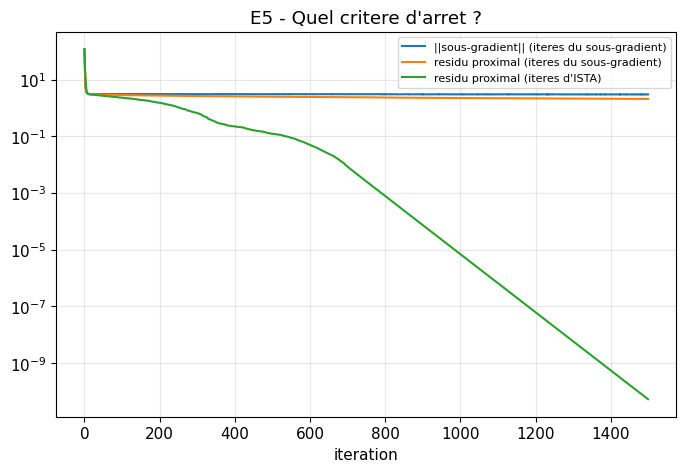

norme du sous-gradient : min = 2.95, derniere valeur = 3.00 ; residu proximal ISTA : derniere valeur = 5.3e-11


In [156]:
# (a) Effet du point de départ sur le sous-gradient et sur ISTA ; (b) comparaison de trois critères d'arrêt possibles.
rows = []
for name, init in [('x0 = 0', 'zero'), ('x0 ~ N(0,1)', 'rand')]:
    sg, isl = [], []
    for I in instances:
        x0_ = np.zeros(1000) if init == 'zero' else I['x0']
        sg.append(max(subgradient_descent(I['A'], I['b'], ALPHA, x0_, 1000, lambda k: 0.1 / np.sqrt(k + 1))[1][-1] - I['fstar'], 1e-16))
        isl.append(max(ista(I['A'], I['b'], ALPHA, x0_, 1000)[1][-1] - I['fstar'], 1e-16))
    rows.append(dict(initialisation=name, sous_gradient=np.median(sg), ISTA=np.median(isl)))
display(pd.DataFrame(rows).set_index('initialisation'))

I = instances[0]; x = I['x0'].copy(); naif, rp_sg = [], []
for k in range(1500):
    g = grad_smooth(I['A'], I['b'], x) + ALPHA * np.sign(x)
    naif.append(np.linalg.norm(g)); rp_sg.append(prox_residual(I['A'], I['b'], x, ALPHA, I['L'])); x = x - 0.1 / np.sqrt(k + 1) * g
x = I['x0'].copy(); rp_is = []
for k in range(1500):
    rp_is.append(prox_residual(I['A'], I['b'], x, ALPHA, I['L'])); x = soft(x - grad_smooth(I['A'], I['b'], x) / I['L'], ALPHA / I['L'])
plt.figure(figsize=(8, 5))
plt.plot(naif, label='||sous-gradient|| (iteres du sous-gradient)'); plt.plot(rp_sg, label='residu proximal (iteres du sous-gradient)'); plt.plot(rp_is, label="residu proximal (iteres d'ISTA)")
plt.yscale('log'); plt.xlabel('iteration'); plt.title("E5 - Quel critere d'arret ?"); plt.legend(fontsize=8); plt.show()
print("norme du sous-gradient : min = %.2f, derniere valeur = %.2f ; residu proximal ISTA : derniere valeur = %.1e" % (min(naif), naif[-1], rp_is[-1]))

> **Résultats mesurés:** Initialisation : le sous-gradient atteint f − f* ≈ **0,18** depuis x₀ = 0 contre **28,9** depuis x₀ aléatoire ; ISTA converge dans les deux cas (≈ 10⁻¹⁵ et 3·10⁻¹⁰). Critère d'arrêt : la norme du sous-gradient reste ≈ **3** et ne tend jamais vers 0 ; le résidu proximal d'ISTA descend à ≈ 5·10⁻¹¹.


> **Interprétation:** (a) Pour le sous-gradient, le point de départ **domine le résultat** : partir de zéro évite d'avoir à « ramener » 990 coordonnées à 0 avec des pas de s·α. Comme on ne sait presque jamais partir de la bonne solution, c'est une **faiblesse de fiabilité** (le résultat dépend d'un réglage qu'on ne contrôle pas), alors qu'ISTA y est insensible. (b) La norme du sous-gradient **ne peut pas servir de critère d'arrêt** : même à l'optimum elle ne s'annule pas (le sous-gradient choisi n'est pas celui de norme minimale). Le résidu proximal, lui, s'annule si et seulement si le point est optimal : c'est le critère à utiliser, avec une tolérance (par exemple 10⁻⁶).


> **Limite:** Partir de zéro est plus favorable ici parce que la vraie solution est parcimonieuse et centrée en 0 ; sur un autre problème, 0 pourrait être un mauvais point de départ.
>  Un bon critère d'arrêt doit s'annuler à l'optimum : pour le LASSO, c'est le résidu proximal et pas la norme du sous-gradient.

In [157]:
#je restaure les réglages graphiques d'origine du notebook pour les sections suivantes
plt.rcParams.update(OLD_RC)

---
# Synthèse : applicabilité, fiabilité, limites, améliorations

### Tableau récapitulatif (sur ce problème : m = 100, n = 1000, α = 0,1, matrices gaussiennes, sans bruit)
| Méthode | Adaptée si… | Fiabilité observée | Critère d'arrêt | Limite principale |
|---|---|---|---|---|
| Sous-gradient, pas constant (notebook) | on veut un code très court et une valeur approchée suffit | **faible** : plateau 5× trop haut (E1), dépend du pas et du départ (E1, E5) | aucun critère valable (E5) | ne converge pas, pas de vrais zéros |
| Sous-gradient, pas décroissant | on peut attendre longtemps | théorie : converge ; pratique : très lente (E1) | aucun critère simple | vitesse en 1/√k (notes EE227C, ch. 2, théorème 2.6) |
| Gradient stochastique par mini-batch | m très grand (non testé ici) | sur m = 100 : sans avantage, plancher de bruit (E3) | comme ci-dessus | bruit, pas à régler selon b |
| **ISTA** | lisse + ℓ1, L connue ou estimable | **bonne** : 10/10 instances atteignent 10⁻⁶ (médiane 10⁻¹⁶) (E2) | **résidu proximal** (E5) | lent (≈ 800 itérations) |
| **FISTA** | idem, quand la vitesse compte | **bonne** : même précision en ≈ 250 itérations (E2) | résidu proximal | non monotone |

### Applicabilité
Le problème est convexe : un point stationnaire est un minimum global, donc les méthodes ne risquent pas de rester coincées dans un minimum local. Le terme ℓ1 est non lisse : la descente de gradient pure ne s'applique pas telle quelle. Il faut soit un sous-gradient (on perd la garantie de descente), soit un opérateur proximal (cours p. 120-123), qui garde de bonnes garanties. La lissité de la partie quadratique est satisfaite (L ≈ 17). La forte convexité **n'est pas** satisfaite (m < n) : on ne peut donc pas invoquer la convergence linéaire des notes EE227C (ch. 3). On l'observe pourtant en pratique pour ISTA après identification du support .

### Fiabilité (ce que j'affirme et ce que je n'affirme pas)
* **Mesuré :** ISTA/FISTA convergent vers la valeur de scikit-learn (écart ≈ 10⁻¹² sur l'instance vérifiée) ; le sous-gradient du notebook ne converge pas (plateau de f − f* ≈ 4,9) ; son résultat dépend fortement du pas et de l'initialisation ; sur ce petit problème, le gradient stochastique n'apporte rien.
* **Non testé :** données bruitées, colonnes de A corrélées, autres dimensions, très grand m, choix de α par validation croisée, pas décroissant sur de longues durées, méthodes à variance réduite.
* **Niveau de confiance :** élevé pour « ISTA/FISTA sont plus fiables que le sous-gradient sur ce problème » (écart de plusieurs ordres de grandeur, 10 instances, vérification externe). Plus faible pour tout ce qui concerne le mini-batch (5 instances, grille de pas limitée, m minuscule).

### Amélioration à retenir
**Remplacer le sous-gradient par ISTA/FISTA, avec le résidu proximal comme critère d'arrêt.** Je la justifie par des limites que j'ai *observées* (plateau, dépendance à l'initialisation, absence de critère d'arrêt) et pas par goût de la sophistication. Il existe d'autres méthodes (descente de coordonnées, ADMM, LARS ), mais elles ne sont pas nécessaires pour ce problème.

### Questions que le professeur pourrait poser
1. **« Pourquoi le sous-gradient ne converge-t-il pas avec un pas constant ? »**

 — Le sous-gradient de |x| vaut ±1 près de 0 et ne tend pas vers 0, donc le pas ne s'annule jamais et chaque coordonnée oscille autour de 0. De plus, l'objectif n'est pas garanti de décroître (E1, E5).
2. **« Pourquoi ISTA donne-t-il de vrais zéros ? »**

— Parce que le seuillage doux (cours p. 132) met exactement à 0 toute coordonnée de valeur absolue inférieure à α/L.
3. **« Quel lien entre ISTA et le gradient projeté du cours ? »**

 — C'est la même structure : un pas de gradient sur la partie lisse, puis l'opérateur proximal de la partie non lisse à la place de la projection (cours p. 123).
4. **« Quand le gradient stochastique est-il utile ? »**

 — Quand le gradient complet est coûteux (m très grand). Sur m = 100 il n'apporte rien et ajoute un plancher d'erreur (E3), comme le prévoit la formule du cours avec pas constant ( p. 118).
5. **« Le LASSO est-il non convexe ? »**

— Non : il est convexe et non lisse. Les difficultés viennent de la non-différentiabilité, pas de la non-convexité.

6. **« Pourquoi la convergence linéaire du cours ne s'applique-t-elle pas ? »**

— Parce que f n'est pas fortement convexe quand m < n (notes EE227C, ch. 3) : la hessienne de la partie lisse a un noyau de dimension 900.

7. **« Qu'est-ce qui garantit que votre solution de référence est correcte ? »**

 — Elle est comparée à scikit-learn, qui minimise la même fonction : les deux coïncident à 10⁻¹² près.